In [66]:
from pathlib import Path
import pandas as pd
import numpy as np
import os
import json
import matplotlib.pyplot as plt

# MIMIC-IV FULL DATASET

DATA_ROOT = Path(
    "/Users/tejaramidi/Documents/fyp_icu/data/raw/mimic-iv-full"
)

HOSP_DIR = DATA_ROOT / "hosp"
ICU_DIR = DATA_ROOT / "icu"

print("Dataset root :", DATA_ROOT)
print("Hospital dir :", HOSP_DIR)
print("ICU dir      :", ICU_DIR)

print("\nPath checks:")
print("Dataset exists :", DATA_ROOT.exists())
print("HOSP exists    :", HOSP_DIR.exists())
print("ICU exists     :", ICU_DIR.exists())

Dataset root : /Users/tejaramidi/Documents/fyp_icu/data/raw/mimic-iv-full
Hospital dir : /Users/tejaramidi/Documents/fyp_icu/data/raw/mimic-iv-full/hosp
ICU dir      : /Users/tejaramidi/Documents/fyp_icu/data/raw/mimic-iv-full/icu

Path checks:
Dataset exists : True
HOSP exists    : True
ICU exists     : True


In [67]:
files = []

for folder in [HOSP_DIR, ICU_DIR]:
    for file in sorted(folder.iterdir()):
        if file.is_file():
            size_gb = file.stat().st_size / (1024**3)
            files.append({
                "folder": folder.name,
                "file": file.name,
                "size_gb": round(size_gb, 3)
            })

files.sort(key=lambda x: x["size_gb"], reverse=True)
file_inventory = pd.DataFrame(files)

file_inventory

,folder,file,size_gb
0,icu,chartevents.csv.gz,3.262
1,hosp,labevents.csv.gz,2.415
2,hosp,emar.csv.gz,0.756
3,hosp,emar_detail.csv.gz,0.697
4,hosp,poe.csv.gz,0.621
5,hosp,prescriptions.csv.gz,0.565
6,hosp,pharmacy.csv.gz,0.490
7,icu,inputevents.csv.gz,0.374
8,icu,ingredientevents.csv.gz,0.290
9,hosp,microbiologyevents.csv.gz,0.110


In [68]:
# Create a compact inventory of the available MIMIC-IV tables

table_groups = {
    "ICU": sorted(ICU_DIR.glob("*.csv.gz")),
    "HOSP": sorted(HOSP_DIR.glob("*.csv.gz"))
}

for group, files in table_groups.items():
    print(f"\n{group} TABLES ({len(files)})")
    print("-" * 50)
    for f in files:
        print(f.stem.replace(".csv", ""))


ICU TABLES (9)
--------------------------------------------------
caregiver
chartevents
d_items
datetimeevents
icustays
ingredientevents
inputevents
outputevents
procedureevents

HOSP TABLES (22)
--------------------------------------------------
admissions
d_hcpcs
d_icd_diagnoses
d_icd_procedures
d_labitems
diagnoses_icd
drgcodes
emar
emar_detail
hcpcsevents
labevents
microbiologyevents
omr
patients
pharmacy
poe
poe_detail
prescriptions
procedures_icd
provider
services
transfers


In [69]:
# Inspect the schema of every MIMIC-IV table without loading the data

schema_rows = []

for group, files in table_groups.items():
    for file in files:
        header = pd.read_csv(file, compression="gzip", nrows=0)

        for column, dtype in header.dtypes.items():
            schema_rows.append({
                "domain": group,
                "table": file.stem.replace(".csv", ""),
                "column": column,
                "dtype": str(dtype)
            })

schema_df = pd.DataFrame(schema_rows)

print(f"Total columns discovered: {len(schema_df)}")
print(f"Total tables discovered : {schema_df['table'].nunique()}")

schema_df

Total columns discovered: 342
Total tables discovered : 31


,domain,table,column,dtype
0,ICU,caregiver,caregiver_id,object
1,ICU,chartevents,subject_id,object
2,ICU,chartevents,hadm_id,object
3,ICU,chartevents,stay_id,object
4,ICU,chartevents,caregiver_id,object
...,...,...,...,...
337,HOSP,transfers,transfer_id,object
338,HOSP,transfers,eventtype,object
339,HOSP,transfers,careunit,object
340,HOSP,transfers,intime,object


In [70]:
# Show the schema of the core patient, admission, ICU, event, and outcome tables

core_tables = [
    "patients",
    "admissions",
    "icustays",
    "chartevents",
    "labevents",
    "inputevents",
    "outputevents",
    "procedureevents",
    "diagnoses_icd",
    "microbiologyevents"
]

core_schema = schema_df[schema_df["table"].isin(core_tables)]

for table in core_tables:
    print(table.upper())
    
    display(
        core_schema[core_schema["table"] == table][
            ["domain", "column", "dtype"]
        ].reset_index(drop=True)
    )

PATIENTS


,domain,column,dtype
0,HOSP,subject_id,object
1,HOSP,gender,object
2,HOSP,anchor_age,object
3,HOSP,anchor_year,object
4,HOSP,anchor_year_group,object
5,HOSP,dod,object


ADMISSIONS


,domain,column,dtype
0,HOSP,subject_id,object
1,HOSP,hadm_id,object
2,HOSP,admittime,object
3,HOSP,dischtime,object
4,HOSP,deathtime,object
5,HOSP,admission_type,object
6,HOSP,admit_provider_id,object
7,HOSP,admission_location,object
8,HOSP,discharge_location,object
9,HOSP,insurance,object


ICUSTAYS


,domain,column,dtype
0,ICU,subject_id,object
1,ICU,hadm_id,object
2,ICU,stay_id,object
3,ICU,first_careunit,object
4,ICU,last_careunit,object
5,ICU,intime,object
6,ICU,outtime,object
7,ICU,los,object


... (10 outputs left out)

DIAGNOSES_ICD


,domain,column,dtype
0,HOSP,subject_id,object
1,HOSP,hadm_id,object
2,HOSP,seq_num,object
3,HOSP,icd_code,object
4,HOSP,icd_version,object


MICROBIOLOGYEVENTS


,domain,column,dtype
0,HOSP,microevent_id,object
1,HOSP,subject_id,object
2,HOSP,hadm_id,object
3,HOSP,micro_specimen_id,object
4,HOSP,order_provider_id,object
5,HOSP,chartdate,object
6,HOSP,charttime,object
7,HOSP,spec_itemid,object
8,HOSP,spec_type_desc,object
9,HOSP,test_seq,object


In [72]:
# Check row counts and basic temporal coverage of the core tables

core_files = {
    "patients": HOSP_DIR / "patients.csv.gz",
    "admissions": HOSP_DIR / "admissions.csv.gz",
    "icustays": ICU_DIR / "icustays.csv.gz",
    "chartevents": ICU_DIR / "chartevents.csv.gz",
    "labevents": HOSP_DIR / "labevents.csv.gz",
    "inputevents": ICU_DIR / "inputevents.csv.gz",
    "outputevents": ICU_DIR / "outputevents.csv.gz",
    "procedureevents": ICU_DIR / "procedureevents.csv.gz",
}

for name, file in core_files.items():
    df = pd.read_csv(file, compression="gzip", usecols=lambda c: c in [
        "subject_id", "hadm_id", "stay_id",
        "charttime", "starttime", "endtime",
        "admittime", "dischtime", "intime", "outtime"
    ])
    
    print(f"\n{name}")
    print(f"Rows: {len(df):,}")
    
    for col in ["subject_id", "hadm_id", "stay_id"]:
        if col in df.columns:
            print(f"Unique {col}: {df[col].nunique():,}")
    
    for col in ["admittime", "intime", "charttime", "starttime"]:
        if col in df.columns:
            values = pd.to_datetime(df[col], errors="coerce")
            print(f"{col}: {values.min()} → {values.max()}")


patients
Rows: 364,627
Unique subject_id: 364,627

admissions
Rows: 546,028
Unique subject_id: 223,452
Unique hadm_id: 546,028
admittime: 2105-10-04 17:26:00 → 2214-12-15 19:11:00

icustays
Rows: 94,458
Unique subject_id: 65,366
Unique hadm_id: 85,242
Unique stay_id: 94,458
intime: 2110-01-11 10:16:06 → 2214-07-22 17:05:53

chartevents
Rows: 432,997,491
Unique subject_id: 65,366
Unique hadm_id: 85,242
Unique stay_id: 94,450
charttime: 2109-07-25 00:00:00 → 2214-07-26 16:00:00

labevents
Rows: 158,374,764
Unique subject_id: 313,442
Unique hadm_id: 447,689
charttime: 2105-01-19 12:01:00 → 2215-01-12 11:45:00

inputevents
Rows: 10,953,713
Unique subject_id: 58,696
Unique hadm_id: 76,510
Unique stay_id: 84,345
starttime: 2110-01-11 12:30:00 → 2211-11-27 08:01:00

outputevents
Rows: 5,359,395
Unique subject_id: 64,292
Unique hadm_id: 83,023
Unique stay_id: 91,510
charttime: 2110-01-11 12:30:00 → 2214-07-26 14:00:00

procedureevents
Rows: 808,706
Unique subject_id: 58,794
Unique hadm_id: 76

In [ ]:
# Examine ICU stay duration and the number of ICU stays per patient

icustays = pd.read_csv(
    ICU_DIR / "icustays.csv.gz",
    compression="gzip",
    usecols=[
        "subject_id",
        "hadm_id",
        "stay_id",
        "intime",
        "outtime",
        "los"
    ]
)

icustays["intime"] = pd.to_datetime(icustays["intime"])
icustays["outtime"] = pd.to_datetime(icustays["outtime"])
icustays["los_hours"] = (
    icustays["outtime"] - icustays["intime"]
).dt.total_seconds() / 3600

print("ICU stays:", len(icustays))
print("Unique patients:", icustays["subject_id"].nunique())
print("Patients with multiple ICU stays:",
      (icustays.groupby("subject_id").size() > 1).sum())

print("\nICU stay duration (hours):")
display(icustays["los_hours"].describe())

print("\nICU stay duration (days):")
display((icustays["los_hours"] / 24).describe())

print("\nICU stays per patient:")
display(
    icustays.groupby("subject_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("number_of_stays")
    .reset_index(name="patients")
)

ICU stays: 94458
Unique patients: 65366
Patients with multiple ICU stays: 16242

ICU stay duration (hours):


count    94444.000000
mean        87.120596
std        129.659365
min          0.030000
25%         26.309097
50%         47.175556
75%         92.701806
max       5433.673889
Name: los_hours, dtype: float64


ICU stay duration (days):


count    94444.000000
mean         3.630025
std          5.402474
min          0.001250
25%          1.096212
50%          1.965648
75%          3.862575
max        226.403079
Name: los_hours, dtype: float64


ICU stays per patient:


,number_of_stays,patients
0,1,49124
1,2,10341
2,3,3206
3,4,1290
4,5,580
5,6,308
6,7,158
7,8,110
8,9,55
9,10,53


In [ ]:
# Investigate ICU stays with missing or invalid duration values

invalid_stays = icustays[
    icustays["intime"].isna()
    | icustays["outtime"].isna()
    | icustays["los_hours"].isna()
    | (icustays["los_hours"] <= 0)
]

print("Invalid/missing ICU stays:", len(invalid_stays))

display(
    invalid_stays[
        ["subject_id", "hadm_id", "stay_id", "intime", "outtime", "los", "los_hours"]
    ]
)

Invalid/missing ICU stays: 14


,subject_id,hadm_id,stay_id,intime,outtime,los,los_hours
4486,10492274,29238609,38475410,2165-03-18 09:34:15,NaT,NaN,NaN
8155,10882284,28910170,30924165,2125-04-23 03:13:54,NaT,NaN,NaN
15758,11661851,24632782,37339160,2173-01-17 18:24:31,NaT,NaN,NaN
16892,11783844,26555335,38888759,2157-10-27 05:59:30,NaT,NaN,NaN
24344,12590282,27383443,38914513,2185-04-03 02:19:38,NaT,NaN,NaN
40939,14330929,27393728,31619283,2188-06-12 16:22:17,NaT,NaN,NaN
54594,15777534,23340499,37403535,2126-03-09 22:46:50,NaT,NaN,NaN
55595,15882332,24693580,36353950,2178-03-27 19:18:14,NaT,NaN,NaN
57792,16117624,26745154,33009457,2180-08-17 17:29:29,NaT,NaN,NaN
59939,16348177,22166548,34986686,2151-10-05 18:47:26,NaT,NaN,NaN


In [ ]:
# Check whether the 14 stays with missing outtime contain usable ICU observations

invalid_ids = invalid_stays["stay_id"].tolist()

checks = {}

for name, file in {
    "chartevents": ICU_DIR / "chartevents.csv.gz",
    "inputevents": ICU_DIR / "inputevents.csv.gz",
    "outputevents": ICU_DIR / "outputevents.csv.gz",
    "procedureevents": ICU_DIR / "procedureevents.csv.gz"
}.items():

    usecols = ["stay_id"]

    df = pd.read_csv(
        file,
        compression="gzip",
        usecols=usecols
    )

    matched = df[df["stay_id"].isin(invalid_ids)]

    checks[name] = {
        "rows": len(matched),
        "stays_found": matched["stay_id"].nunique()
    }

    print(
        f"{name:16s} | "
        f"rows = {len(matched):,} | "
        f"stays = {matched['stay_id'].nunique()}"
    )

chartevents      | rows = 185,161 | stays = 14
inputevents      | rows = 9,086 | stays = 14
outputevents     | rows = 1,488 | stays = 14
procedureevents  | rows = 221 | stays = 14


In [ ]:
# Compare the last recorded clinical event with the ICU admission time for the 14 incomplete stays

invalid_ids = set(invalid_stays["stay_id"])

event_ranges = []

for name, file, time_col in [
    ("chartevents", ICU_DIR / "chartevents.csv.gz", "charttime"),
    ("inputevents", ICU_DIR / "inputevents.csv.gz", "endtime"),
    ("outputevents", ICU_DIR / "outputevents.csv.gz", "charttime"),
    ("procedureevents", ICU_DIR / "procedureevents.csv.gz", "endtime")
]:
    df = pd.read_csv(
        file,
        compression="gzip",
        usecols=["stay_id", time_col]
    )

    df = df[df["stay_id"].isin(invalid_ids)].copy()
    df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

    grouped = (
        df.groupby("stay_id")[time_col]
        .agg(first_event="min", last_event="max")
        .reset_index()
    )

    grouped["source"] = name
    event_ranges.append(grouped)

event_ranges = pd.concat(event_ranges, ignore_index=True)

display(
    event_ranges.sort_values(["stay_id", "source"])
)

,stay_id,first_event,last_event,source
0,30924165,2125-04-23 03:00:00,2125-05-18 16:00:00,chartevents
14,30924165,2125-04-23 03:52:00,2125-05-18 16:59:00,inputevents
28,30924165,2125-04-23 03:52:00,2125-05-18 15:00:00,outputevents
42,30924165,2125-04-26 07:58:00,2125-05-18 17:00:00,procedureevents
1,31619283,2188-06-12 16:22:00,2188-06-23 21:00:00,chartevents
15,31619283,2188-06-12 16:50:00,2188-06-23 23:50:00,inputevents
29,31619283,2188-06-12 21:26:00,2188-06-23 16:00:00,outputevents
43,31619283,2188-06-12 18:43:00,2188-06-23 23:51:00,procedureevents
2,33009457,2180-08-17 17:00:00,2180-08-24 08:55:00,chartevents
16,33009457,2180-08-17 18:13:00,2180-08-24 08:01:00,inputevents


In [ ]:
# Find the most frequently recorded ICU chart items

item_counts = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["itemid"]
)["itemid"].value_counts()

print("Unique chart itemids:", f"{item_counts.size:,}")

display(
    item_counts.head(50)
    .rename("record_count")
    .reset_index()
    .rename(columns={"index": "itemid"})
)

Unique chart itemids: 2,311


,itemid,record_count
0,227969,12869833
1,220045,8752069
2,220210,8636655
3,220277,8567015
4,220048,7947289
5,224650,7049295
6,220179,5378740
7,220180,5377689
8,220181,5372922
9,227958,5021996


In [ ]:
# Map the most frequent chart itemids to their clinical meanings

top_itemids = item_counts.head(50).index.tolist()

d_items = pd.read_csv(
    ICU_DIR / "d_items.csv.gz",
    compression="gzip"
)

top_items = d_items[
    d_items["itemid"].isin(top_itemids)
].copy()

display(
    top_items[
        [
            "itemid",
            "label",
            "abbreviation",
            "linksto",
            "category",
            "unitname"
        ]
    ]
    .sort_values(
        "itemid"
    )
    .reset_index(drop=True)
)

,itemid,label,abbreviation,linksto,category,unitname
0,220045,Heart Rate,HR,chartevents,Routine Vital Signs,bpm
1,220048,Heart Rhythm,Heart Rhythm,chartevents,Routine Vital Signs,NaN
2,220050,Arterial Blood Pressure systolic,ABPs,chartevents,Routine Vital Signs,mmHg
3,220051,Arterial Blood Pressure diastolic,ABPd,chartevents,Routine Vital Signs,mmHg
4,220052,Arterial Blood Pressure mean,ABPm,chartevents,Routine Vital Signs,mmHg
5,220179,Non Invasive Blood Pressure systolic,NBPs,chartevents,Routine Vital Signs,mmHg
6,220180,Non Invasive Blood Pressure diastolic,NBPd,chartevents,Routine Vital Signs,mmHg
7,220181,Non Invasive Blood Pressure mean,NBPm,chartevents,Routine Vital Signs,mmHg
8,220210,Respiratory Rate,RR,chartevents,Respiratory,insp/min
9,220277,O2 saturation pulseoxymetry,SpO2,chartevents,Respiratory,%


In [ ]:
# Find candidate physiological measurements from d_items

physio_keywords = [
    "heart rate",
    "blood pressure",
    "respiratory rate",
    "oxygen saturation",
    "spo2",
    "temperature",
    "gcs",
    "glucose",
    "lactate",
    "creatinine",
    "wbc",
    "hemoglobin",
    "platelet",
    "bilirubin",
    "urine output",
    "oxygen",
    "fio2",
    "peep"
]

pattern = "|".join(physio_keywords)

physio_items = d_items[
    d_items["label"]
    .fillna("")
    .str.lower()
    .str.contains(pattern, regex=True)
].copy()

print("Candidate physiological items:", len(physio_items))

display(
    physio_items[
        [
            "itemid",
            "label",
            "abbreviation",
            "linksto",
            "category",
            "unitname"
        ]
    ]
    .sort_values(["category", "label"])
    .reset_index(drop=True)
)

Candidate physiological items: 104


,itemid,label,abbreviation,linksto,category,unitname
0,227537,ART Blood Pressure Alarm - High,ART BP Alarm - High,chartevents,Alarms,mmHg
1,227538,ART Blood Pressure Alarm - Low,ART BP Alarm - Low,chartevents,Alarms,mmHg
2,227539,ART Blood Pressure Alarm Source,ART BP Alarm Source,chartevents,Alarms,NaN
3,220058,Arterial Blood Pressure Alarm - High,ABP Alarm - High,chartevents,Alarms,mmHg
4,220056,Arterial Blood Pressure Alarm - Low,ABP Alarm - Low,chartevents,Alarms,mmHg
...,...,...,...,...,...,...
99,227062,WBC_ApacheIV,WBC_ApacheIV,chartevents,Scores - APACHE IV (2),NaN
100,224027,Skin Temperature,Skin Temp,chartevents,Skin - Assessment,NaN
101,228192,Oxygenator Sweep Rate,Oxygenator Sweep Rate,chartevents,Tandem Heart,L/min
102,228193,Oxygenator/ECMO,Oxygenator/ECMO,chartevents,Tandem Heart,NaN


In [ ]:
# Candidate direct physiological measurements

exclude_keywords = [
    "alarm",
    "apache",
    "score",
    "ncp",
    "care plan",
    "expected outcome",
    "intervention",
    "education",
    "restraint",
    "safety",
    "device status",
    "management",
    "assessment"
]

candidate_items = physio_items.copy()

exclude_pattern = "|".join(exclude_keywords)

candidate_items = candidate_items[
    ~candidate_items["label"]
    .fillna("")
    .str.lower()
    .str.contains(exclude_pattern, regex=True)
].copy()

print("Candidate direct physiological measurements:", len(candidate_items))

display(
    candidate_items[
        [
            "itemid",
            "label",
            "abbreviation",
            "category",
            "unitname"
        ]
    ]
    .sort_values(["category", "label"])
    .reset_index(drop=True)
)

Candidate direct physiological measurements: 69


,itemid,label,abbreviation,category,unitname
0,226253,SpO2 Desat Limit,SpO2 Desat Limit,Alarms,%
1,226369,OR Platelet Intake,OR Platelet Intake,Blood Products/Colloids,mL
2,227071,PACU Platelet Intake,PACU Platelet Intake,Blood Products/Colloids,mL
3,225170,Platelets,Platelets,Blood Products/Colloids,mL
4,229841,FiO2 (CH),FiO2 (CH),ECMO,%
...,...,...,...,...,...
64,224642,Temperature Site,Temp Site,Routine Vital Signs,NaN
65,224027,Skin Temperature,Skin Temp,Skin - Assessment,NaN
66,228192,Oxygenator Sweep Rate,Oxygenator Sweep Rate,Tandem Heart,L/min
67,228193,Oxygenator/ECMO,Oxygenator/ECMO,Tandem Heart,NaN


In [ ]:
# Measure actual coverage of candidate physiological items
# We only read itemid from the 432M-row chartevents table.

candidate_ids = set(candidate_items["itemid"])

candidate_counts = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["itemid"]
)["itemid"].value_counts()

coverage = (
    candidate_counts
    .reindex(candidate_ids)
    .fillna(0)
    .astype(int)
    .rename("record_count")
    .reset_index()
    .rename(columns={"index": "itemid"})
)

coverage = coverage.merge(
    candidate_items[
        ["itemid", "label", "abbreviation", "category", "unitname"]
    ],
    on="itemid",
    how="left"
)

coverage["percent_of_candidate_records"] = (
    coverage["record_count"] /
    coverage["record_count"].sum() * 100
)

display(
    coverage
    .sort_values("record_count", ascending=False)
    .reset_index(drop=True)
)

,itemid,record_count,label,abbreviation,category,unitname,percent_of_candidate_records
0,220045,8752069,Heart Rate,HR,Routine Vital Signs,bpm,13.660574
1,220210,8636655,Respiratory Rate,RR,Respiratory,insp/min,13.480431
2,220179,5378740,Non Invasive Blood Pressure systolic,NBPs,Routine Vital Signs,mmHg,8.395349
3,220180,5377689,Non Invasive Blood Pressure diastolic,NBPd,Routine Vital Signs,mmHg,8.393709
4,220181,5372922,Non Invasive Blood Pressure mean,NBPm,Routine Vital Signs,mmHg,8.386268
...,...,...,...,...,...,...,...
64,220968,0,Dextrose 10% / Ringers Lactate,Dextrose 10% / Ringers Lactate,Fluids - Other (Not In Use),mL,0.000000
65,220967,0,Dextrose 5% / Ringers Lactate,Dextrose 5% / Ringers Lactate,Fluids - Other (Not In Use),mL,0.000000
66,225302,0,Pre-Oxygentated (Intubation),Pre-Oxygentated (Intubation),Intubation,NaN,0.000000
67,228388,0,Glucose (whole blood) (soft),Glucose (whole blood) (soft),Labs,NaN,0.000000


In [ ]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [ ]:
# Observation density per ICU stay

top_candidates = coverage[
    coverage["stays_with_measurement"] > 0
].copy()

density = (
    stay_coverage[
        stay_coverage["itemid"].isin(top_candidates["itemid"])
    ]
    .groupby(["itemid", "stay_id"])
    .size()
    .groupby("itemid")
    .agg(
        median_observations_per_stay="median",
        mean_observations_per_stay="mean"
    )
    .reset_index()
)

density = density.merge(
    top_candidates[
        ["itemid", "label", "record_count", "stays_with_measurement",
         "stay_coverage_percent"]
    ],
    on="itemid",
    how="left"
)

display(
    density.sort_values(
        "stays_with_measurement",
        ascending=False
    ).reset_index(drop=True)
)

,itemid,median_observations_per_stay,mean_observations_per_stay,label,record_count,stays_with_measurement,stay_coverage_percent
0,220045,50.0,92.676271,Heart Rate,8752069,94437,99.977768
1,220210,49.0,91.554000,Respiratory Rate,8636655,94334,99.868725
2,220739,12.0,23.535972,GCS - Eye Opening,2209510,93878,99.385970
3,223900,12.0,23.493224,GCS - Verbal Response,2205121,93862,99.369032
4,223901,12.0,23.436853,GCS - Motor Response,2199619,93853,99.359504
5,224642,13.0,26.699768,Temperature Site,2500193,93641,99.135065
6,224027,7.0,13.450660,Skin Temperature,1256749,93434,98.915920
7,226253,5.0,8.696865,SpO2 Desat Limit,810687,93216,98.685130
8,220181,34.0,57.672892,Non Invasive Blood Pressure mean,5372922,93162,98.627962
9,220179,34.0,57.745880,Non Invasive Blood Pressure systolic,5378740,93145,98.609964


In [ ]:
# Inspect the main candidate physiological measurements
# that have strong ICU coverage.

important_keywords = [
    "heart rate",
    "respiratory rate",
    "oxygen saturation",
    "spo2",
    "temperature",
    "blood pressure",
    "creatinine",
    "glucose",
    "hemoglobin",
    "wbc",
    "platelet",
    "bilirubin"
]

important = candidate_items[
    candidate_items["label"]
    .fillna("")
    .str.lower()
    .str.contains("|".join(important_keywords), regex=True)
].copy()

important = important.merge(
    coverage[
        [
            "itemid",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ],
    on="itemid",
    how="left"
)

display(
    important[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values("record_count", ascending=False)
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220179,Non Invasive Blood Pressure systolic,Routine Vital Signs,mmHg,5378740,93145,98.609964
3,220180,Non Invasive Blood Pressure diastolic,Routine Vital Signs,mmHg,5377689,93140,98.604671
4,220181,Non Invasive Blood Pressure mean,Routine Vital Signs,mmHg,5372922,93162,98.627962
5,220052,Arterial Blood Pressure mean,Routine Vital Signs,mmHg,3096934,36273,38.401194
6,220050,Arterial Blood Pressure systolic,Routine Vital Signs,mmHg,3087686,36028,38.141820
7,220051,Arterial Blood Pressure diastolic,Routine Vital Signs,mmHg,3087261,36036,38.150289
8,224642,Temperature Site,Routine Vital Signs,NaN,2500193,93641,99.135065
9,223761,Temperature Fahrenheit,Routine Vital Signs,°F,2055040,92837,98.283893


In [ ]:
spo2_items = d_items[
    d_items["label"]
    .fillna("")
    .str.contains(
        "oxygen saturation|spo2|o2 saturation",
        case=False,
        regex=True
    )
].copy()

spo2_items = spo2_items.merge(
    coverage[
        [
            "itemid",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ],
    on="itemid",
    how="left"
)

display(
    spo2_items.sort_values(
        "record_count",
        ascending=False
    ).reset_index(drop=True)
)

,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue,record_count,stays_with_measurement,stay_coverage_percent
0,226253,SpO2 Desat Limit,SpO2 Desat Limit,chartevents,Alarms,%,Numeric,NaN,NaN,810687.0,93216.0,98.685130
1,228232,PAR-Oxygen saturation,PAR-Oxygen saturation,chartevents,Routine Vital Signs,NaN,Text,NaN,NaN,16162.0,6271.0,6.638929
2,229862,Forehead SpO2 Sensor in Place,Forehead SpO2 Sensor in Place,chartevents,Routine Vital Signs,NaN,Checkbox,NaN,NaN,1169.0,456.0,0.482754
3,220227,Arterial O2 Saturation,SaO2,chartevents,Labs,%,Numeric,NaN,NaN,NaN,NaN,NaN
4,220277,O2 saturation pulseoxymetry,SpO2,chartevents,Respiratory,%,Numeric,NaN,NaN,NaN,NaN,NaN
5,223769,O2 Saturation Pulseoxymetry Alarm - High,SpO2 Alarm - High,chartevents,Alarms,%,Numeric,NaN,NaN,NaN,NaN,NaN
6,223770,O2 Saturation Pulseoxymetry Alarm - Low,SpO2 Alarm - Low,chartevents,Alarms,%,Numeric,NaN,NaN,NaN,NaN,NaN
7,226860,RA %O2 Saturation (PA Line),RA %O2 Saturation (PA Line),chartevents,PA Line Insertion,%,Numeric,NaN,NaN,NaN,NaN,NaN
8,226861,ART %O2 saturation (PA Line),ART %O2 saturation (PA Line),chartevents,PA Line Insertion,%,Numeric,NaN,NaN,NaN,NaN,NaN
9,226862,PA %O2 Saturation (PA Line),PA %O2 Saturation (PA Line),chartevents,PA Line Insertion,%,Numeric,NaN,NaN,NaN,NaN,NaN


In [ ]:
SPO2_ITEM = 220277

spo2_stats = (
    pd.read_csv(
        ICU_DIR / "chartevents.csv.gz",
        compression="gzip",
        usecols=["stay_id", "itemid"]
    )
    .query("itemid == @SPO2_ITEM")
    .groupby("stay_id")
    .size()
)

print("SpO2 item:", SPO2_ITEM)
print("Total records:", spo2_stats.sum())
print("ICU stays with SpO2:", spo2_stats.size)
print("Median observations/stay:", spo2_stats.median())
print("Mean observations/stay:", round(spo2_stats.mean(), 2))
print(
    "Stay coverage:",
    round(spo2_stats.size / len(icustays) * 100, 2),
    "%"
)

SpO2 item: 220277
Total records: 8567015
ICU stays with SpO2: 94306
Median observations/stay: 49.0
Mean observations/stay: 90.84
Stay coverage: 99.84 %


In [ ]:
# Inspect raw value distributions for core vital signs

CORE_ITEMS = {
    "Heart Rate": 220045,
    "Respiratory Rate": 220210,
    "SpO2": 220277,
    "NIBP Systolic": 220179,
    "NIBP Diastolic": 220180,
    "NIBP Mean": 220181,
}

core_values = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["itemid", "valuenum"]
)

core_values = core_values[
    core_values["itemid"].isin(CORE_ITEMS.values())
].copy()

core_values["feature"] = core_values["itemid"].map(
    {v: k for k, v in CORE_ITEMS.items()}
)

display(
    core_values
    .groupby("feature")["valuenum"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
feature,,,,,,,,
Heart Rate,8752069.0,88.003187,3801.504881,-241395.0,73.0,85.0,98.0,10000000.0
NIBP Diastolic,5377689.0,66.940259,286.644063,-2.0,55.0,64.0,75.0,114109.0
NIBP Mean,5372922.0,86.076028,6119.765307,-22767.0,68.0,78.0,89.0,8999090.0
NIBP Systolic,5378740.0,120.350727,766.037839,-69.0,103.0,117.0,134.0,1025100.0
Respiratory Rate,8636655.0,21.304515,2522.159697,0.0,16.0,19.0,24.0,7000400.0
SpO2,8567015.0,103.852269,7662.742063,-951234.0,95.0,97.0,99.0,9900000.0


In [ ]:
# Count obviously invalid physiological values

VALID_RANGES = {
    "Heart Rate": (20, 250),
    "Respiratory Rate": (4, 80),
    "SpO2": (50, 100),
    "NIBP Systolic": (40, 300),
    "NIBP Diastolic": (20, 200),
    "NIBP Mean": (30, 250),
}

range_check = []

for feature, (low, high) in VALID_RANGES.items():

    values = core_values.loc[
        core_values["feature"] == feature,
        "valuenum"
    ].dropna()

    invalid = ((values < low) | (values > high)).sum()

    range_check.append({
        "feature": feature,
        "total_values": len(values),
        "invalid_values": int(invalid),
        "invalid_percent": round(
            invalid / len(values) * 100, 4
        ),
        "valid_min": low,
        "valid_max": high
    })

range_check = pd.DataFrame(range_check)

display(range_check)

,feature,total_values,invalid_values,invalid_percent,valid_min,valid_max
0,Heart Rate,8752069,3954,0.0452,20,250
1,Respiratory Rate,8636655,34713,0.4019,4,80
2,SpO2,8567015,3251,0.0379,50,100
3,NIBP Systolic,5378740,759,0.0141,40,300
4,NIBP Diastolic,5377689,3553,0.0661,20,200
5,NIBP Mean,5372922,3278,0.0610,30,250


In [ ]:
for feature, (low, high) in VALID_RANGES.items():

    values = core_values.loc[
        core_values["feature"] == feature,
        "valuenum"
    ].dropna()

    invalid_values = values[
        (values < low) | (values > high)
    ]

    print(f"\n{feature}")
    print(f"Invalid count: {len(invalid_values)}")
    print(
        "Smallest invalid values:",
        invalid_values.nsmallest(5).tolist()
    )
    print(
        "Largest invalid values:",
        invalid_values.nlargest(5).tolist()
    )


Heart Rate
Invalid count: 3954
Smallest invalid values: [-241395.0, -88.0, -1.0, 0.0, 0.0]
Largest invalid values: [10000000.0, 5113280.0, 457890.0, 152143.0, 118107.0]

Respiratory Rate
Invalid count: 34713
Smallest invalid values: [0.0, 0.0, 0.0, 0.0, 0.0]
Largest invalid values: [7000400.0, 2355560.0, 545670.0, 237890.0, 176978.0]

SpO2
Invalid count: 3251
Smallest invalid values: [-951234.0, -678.0, -272.0, -21.0, -8.0]
Largest invalid values: [9900000.0, 9765430.0, 9710010.0, 8933380.0, 8900000.0]

NIBP Systolic
Invalid count: 759
Smallest invalid values: [-69.0, -2.0, 0.0, 0.0, 0.0]
Largest invalid values: [1025100.0, 1003110.0, 1003070.0, 141146.0, 127106.0]

NIBP Diastolic
Invalid count: 3553
Smallest invalid values: [-2.0, 0.0, 0.0, 0.0, 0.0]
Largest invalid values: [114109.0, 105125.0, 105111.0, 100107.0, 98109.0]

NIBP Mean
Invalid count: 3278
Smallest invalid values: [-22767.0, -6739.0, 0.0, 0.0, 0.0]
Largest invalid values: [8999090.0, 8888890.0, 3333330.0, 3333330.0, 314

In [ ]:
# Convert physiologically invalid observations to NaN
# for analysis only — raw files remain untouched.

cleaned_core = core_values.copy()

for feature, (low, high) in VALID_RANGES.items():

    mask = cleaned_core["feature"] == feature

    invalid_mask = (
        mask &
        (
            (cleaned_core["valuenum"] < low) |
            (cleaned_core["valuenum"] > high)
        )
    )

    cleaned_core.loc[invalid_mask, "valuenum"] = np.nan

print("Invalid values converted to NaN:")
print(
    cleaned_core
    .groupby("feature")["valuenum"]
    .apply(lambda x: x.isna().sum())
)

Invalid values converted to NaN:
feature
Heart Rate           3954
NIBP Diastolic       3553
NIBP Mean            3278
NIBP Systolic         759
Respiratory Rate    34713
SpO2                 3251
Name: valuenum, dtype: int64


In [ ]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [ ]:
# Check timestamp spacing for the core physiological signals

sample_stay = 30101877  # replace with any valid stay_id if needed

sample = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid", "charttime", "valuenum"]
)

sample = sample[
    (sample["stay_id"] == sample_stay) &
    (sample["itemid"].isin(CORE_ITEMS.values()))
].copy()

sample["charttime"] = pd.to_datetime(sample["charttime"])

sample = sample.sort_values("charttime")

sample["hours_since_previous"] = (
    sample.groupby("itemid")["charttime"]
    .diff()
    .dt.total_seconds() / 3600
)

display(
    sample.groupby("itemid")["hours_since_previous"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
itemid,,,,,,,,
220045,76.0,1.010307,0.117693,0.783333,1.0,1.0,1.0,2.000000
220179,76.0,1.010088,0.121931,0.766667,1.0,1.0,1.0,2.000000
220180,76.0,1.010088,0.121931,0.766667,1.0,1.0,1.0,2.000000
220181,76.0,1.010088,0.121931,0.766667,1.0,1.0,1.0,2.000000
220210,77.0,0.997186,0.025277,0.783333,1.0,1.0,1.0,1.033333
220277,76.0,1.010526,0.117279,0.800000,1.0,1.0,1.0,2.000000


In [ ]:
# Convert charttime to hourly timestamps
# and inspect how multiple measurements within the same hour behave.

sample["hour"] = sample["charttime"].dt.floor("h")

hourly_sample = (
    sample
    .groupby(["stay_id", "itemid", "hour"])["valuenum"]
    .median()
    .reset_index()
)

display(hourly_sample.head(20))

,stay_id,itemid,hour,valuenum
0,30101877,220045,2143-03-22 07:00:00,109.0
1,30101877,220045,2143-03-22 08:00:00,93.0
2,30101877,220045,2143-03-22 09:00:00,105.0
3,30101877,220045,2143-03-22 10:00:00,123.0
4,30101877,220045,2143-03-22 11:00:00,94.0
5,30101877,220045,2143-03-22 12:00:00,89.0
6,30101877,220045,2143-03-22 13:00:00,88.0
7,30101877,220045,2143-03-22 14:00:00,107.0
8,30101877,220045,2143-03-22 15:00:00,110.0
9,30101877,220045,2143-03-22 16:00:00,89.0


In [ ]:
# Check missing hourly timestamps for this sample stay and feature

hr_sample = hourly_sample[
    (hourly_sample["stay_id"] == sample_stay) &
    (hourly_sample["itemid"] == CORE_ITEMS["Heart Rate"])
].copy()

full_hours = pd.date_range(
    hr_sample["hour"].min(),
    hr_sample["hour"].max(),
    freq="h"
)

observed_hours = pd.DatetimeIndex(hr_sample["hour"])

missing_hours = full_hours.difference(observed_hours)

print("Expected hourly timestamps :", len(full_hours))
print("Observed hourly timestamps :", len(observed_hours))
print("Missing hourly timestamps  :", len(missing_hours))
print("Missing percentage         :",
      round(len(missing_hours) / len(full_hours) * 100, 2), "%")

Expected hourly timestamps : 78
Observed hourly timestamps : 77
Missing hourly timestamps  : 1
Missing percentage         : 1.28 %


In [ ]:
# Check hourly coverage across a small set of ICU stays

sample_stays = icustays["stay_id"].dropna().head(20).tolist()

coverage_results = []

for stay in sample_stays:

    stay_hr = hourly_sample[
        hourly_sample["stay_id"] == stay
    ]

    if stay_hr.empty:
        continue

    start = stay_hr["hour"].min()
    end = stay_hr["hour"].max()

    expected = len(pd.date_range(start, end, freq="h"))
    observed = stay_hr["hour"].nunique()

    coverage_results.append({
        "stay_id": stay,
        "expected_hours": expected,
        "observed_hours": observed,
        "missing_hours": expected - observed,
        "missing_percent": round(
            (expected - observed) / expected * 100, 2
        )
    })

hourly_coverage = pd.DataFrame(coverage_results)

display(hourly_coverage)

""


In [ ]:
hourly_pivot = (
    hourly_sample
    .pivot_table(
        index=["stay_id", "hour"],
        columns="itemid",
        values="valuenum",
        aggfunc="median"
    )
    .reset_index()
)

hourly_pivot = hourly_pivot.rename(columns={
    220045: "heart_rate",
    220210: "resp_rate",
    220277: "spo2",
    220179: "sbp",
    220180: "dbp",
    220181: "map"
})

display(hourly_pivot.head(20))

itemid,stay_id,hour,heart_rate,sbp,dbp,map,resp_rate,spo2
0,30101877,2143-03-22 07:00:00,109.0,121.0,86.0,93.0,21.0,100.0
1,30101877,2143-03-22 08:00:00,93.0,102.0,49.0,63.0,18.0,100.0
2,30101877,2143-03-22 09:00:00,105.0,147.0,85.0,100.0,19.0,100.0
3,30101877,2143-03-22 10:00:00,123.0,136.0,85.0,96.0,24.0,100.0
4,30101877,2143-03-22 11:00:00,94.0,150.0,76.0,94.0,18.0,100.0
5,30101877,2143-03-22 12:00:00,89.0,136.0,49.0,71.0,20.0,100.0
6,30101877,2143-03-22 13:00:00,88.0,121.0,66.0,79.0,25.0,100.0
7,30101877,2143-03-22 14:00:00,107.0,153.0,74.0,93.0,21.0,100.0
8,30101877,2143-03-22 15:00:00,110.0,155.0,85.0,100.0,23.0,100.0
9,30101877,2143-03-22 16:00:00,89.0,145.0,70.0,87.0,16.0,100.0


In [ ]:
missing_hourly = (
    hourly_pivot[
        ["heart_rate", "sbp", "dbp", "map", "resp_rate", "spo2"]
    ]
    .isna()
    .sum()
    .to_frame("missing_hours")
)

missing_hourly["missing_percent"] = (
    missing_hourly["missing_hours"]
    / len(hourly_pivot)
    * 100
)

display(missing_hourly)

,missing_hours,missing_percent
itemid,,
heart_rate,1,1.282051
sbp,1,1.282051
dbp,1,1.282051
map,1,1.282051
resp_rate,0,0.000000
spo2,1,1.282051


In [ ]:
filled_sample = hourly_pivot.copy()

features = [
    "heart_rate",
    "sbp",
    "dbp",
    "map",
    "resp_rate",
    "spo2"
]

filled_sample[features] = (
    filled_sample[features]
    .ffill()
)

print("Missing values before:")
print(hourly_pivot[features].isna().sum())

print("\nMissing values after forward fill:")
print(filled_sample[features].isna().sum())

Missing values before:
itemid
heart_rate    1
sbp           1
dbp           1
map           1
resp_rate     0
spo2          1
dtype: int64

Missing values after forward fill:
itemid
heart_rate    0
sbp           0
dbp           0
map           0
resp_rate     0
spo2          0
dtype: int64


In [ ]:
# Check the maximum consecutive missing gap for each feature

for feature in features:

    missing = hourly_pivot[feature].isna()

    groups = missing.ne(missing.shift()).cumsum()

    gap_lengths = (
        missing.groupby(groups)
        .sum()
    )

    max_gap = gap_lengths.max()

    print(f"{feature:15s} max missing gap: {int(max_gap)} hour(s)")

heart_rate      max missing gap: 1 hour(s)
sbp             max missing gap: 1 hour(s)
dbp             max missing gap: 1 hour(s)
map             max missing gap: 1 hour(s)
resp_rate       max missing gap: 0 hour(s)
spo2            max missing gap: 1 hour(s)


In [ ]:
CORE_ITEMS

{'Heart Rate': 220045,
 'Respiratory Rate': 220210,
 'SpO2': 220277,
 'NIBP Systolic': 220179,
 'NIBP Diastolic': 220180,
 'NIBP Mean': 220181}

In [ ]:
CHARTEVENTS_PATH = (
    "/Users/tejaramidi/Documents/fyp_icu/"
    "data/raw/mimic-iv-full/icu/chartevents.csv.gz"
)

print("Chartevents path:")
print(CHARTEVENTS_PATH)

print("\nExists:", os.path.exists(CHARTEVENTS_PATH))

Chartevents path:
/Users/tejaramidi/Documents/fyp_icu/data/raw/mimic-iv-full/icu/chartevents.csv.gz

Exists: True


In [ ]:
CORE_ITEM_IDS = list(CORE_ITEMS.values())

CORE_COLUMNS = [
    "subject_id",
    "hadm_id",
    "stay_id",
    "charttime",
    "itemid",
    "valuenum"
]

chunks = []

for chunk in pd.read_csv(
    CHARTEVENTS_PATH,
    usecols=CORE_COLUMNS,
    dtype={
        "subject_id": "Int64",
        "hadm_id": "Int64",
        "stay_id": "Int64",
        "itemid": "Int64",
        "valuenum": "float32"
    },
    parse_dates=["charttime"],
    chunksize=2_000_000
):
    filtered = chunk[chunk["itemid"].isin(CORE_ITEM_IDS)]

    if not filtered.empty:
        chunks.append(filtered)

    print(f"Processed chunk | retained rows: {len(filtered):,}")

core_chartevents = pd.concat(chunks, ignore_index=True)

print("\nCore physiological data:")
print(f"Rows retained: {len(core_chartevents):,}")
print(f"ICU stays:     {core_chartevents['stay_id'].nunique():,}")
print(f"ItemIDs:       {core_chartevents['itemid'].nunique()}")

Processed chunk | retained rows: 194,338
Processed chunk | retained rows: 196,338
Processed chunk | retained rows: 191,820
Processed chunk | retained rows: 191,179
Processed chunk | retained rows: 201,782
Processed chunk | retained rows: 194,583
Processed chunk | retained rows: 194,610
Processed chunk | retained rows: 195,455
Processed chunk | retained rows: 203,964
Processed chunk | retained rows: 185,638
Processed chunk | retained rows: 196,854
Processed chunk | retained rows: 200,140
Processed chunk | retained rows: 199,227
Processed chunk | retained rows: 198,794
Processed chunk | retained rows: 186,680
Processed chunk | retained rows: 200,879
Processed chunk | retained rows: 187,262
Processed chunk | retained rows: 181,344
Processed chunk | retained rows: 188,227
Processed chunk | retained rows: 195,742
Processed chunk | retained rows: 196,646
Processed chunk | retained rows: 194,668
Processed chunk | retained rows: 201,417
Processed chunk | retained rows: 195,942
Processed chunk 

In [ ]:
core_chartevents.groupby("itemid").agg(
    records=("valuenum", "count"),
    stays=("stay_id", "nunique")
).sort_values("records", ascending=False)

,records,stays
itemid,,
220045,8752069,94437
220210,8636655,94334
220277,8567015,94306
220179,5378740,93145
220180,5377689,93140
220181,5372922,93162


In [ ]:
core_chartevents["hour"] = core_chartevents["charttime"].dt.floor("h")

hourly_core = (
    core_chartevents
    .groupby(["stay_id", "hour", "itemid"], as_index=False)["valuenum"]
    .median()
)

print("Raw core records     :", f"{len(core_chartevents):,}")
print("Hourly records       :", f"{len(hourly_core):,}")
print("ICU stays             :", f"{hourly_core['stay_id'].nunique():,}")
print("Unique hourly points :", f"{hourly_core[['stay_id', 'hour']].drop_duplicates().shape[0]:,}")

display(hourly_core.head(10))

Raw core records     : 42,085,090
Hourly records       : 38,572,896
ICU stays             : 94,438
Unique hourly points : 7,912,779


,stay_id,hour,itemid,valuenum
0,30000153,2174-09-29 12:00:00,220045,100.0
1,30000153,2174-09-29 12:00:00,220179,136.0
2,30000153,2174-09-29 12:00:00,220180,74.0
3,30000153,2174-09-29 12:00:00,220181,89.0
4,30000153,2174-09-29 12:00:00,220210,18.0
5,30000153,2174-09-29 12:00:00,220277,100.0
6,30000153,2174-09-29 13:00:00,220045,104.0
7,30000153,2174-09-29 13:00:00,220179,113.0
8,30000153,2174-09-29 13:00:00,220180,77.0
9,30000153,2174-09-29 13:00:00,220181,84.0


In [ ]:
hourly_features = (
    hourly_core
    .pivot_table(
        index=["stay_id", "hour"],
        columns="itemid",
        values="valuenum",
        aggfunc="median"
    )
    .reset_index()
)

hourly_features = hourly_features.rename(columns={
    220045: "heart_rate",
    220210: "resp_rate",
    220277: "spo2",
    220179: "sbp",
    220180: "dbp",
    220181: "map"
})

features = [
    "heart_rate",
    "resp_rate",
    "spo2",
    "sbp",
    "dbp",
    "map"
]

print("Hourly feature matrix shape:", hourly_features.shape)
print("ICU stays:", hourly_features["stay_id"].nunique())

display(hourly_features.head(10))

Hourly feature matrix shape: (7912779, 8)
ICU stays: 94438


itemid,stay_id,hour,heart_rate,sbp,dbp,map,resp_rate,spo2
0,30000153,2174-09-29 12:00:00,100.0,136.0,74.0,89.0,18.0,100.0
1,30000153,2174-09-29 13:00:00,104.0,113.0,77.0,84.0,16.0,100.0
2,30000153,2174-09-29 14:00:00,83.0,NaN,NaN,NaN,16.0,100.0
3,30000153,2174-09-29 15:00:00,92.0,NaN,NaN,NaN,14.0,100.0
4,30000153,2174-09-29 16:00:00,83.0,NaN,NaN,NaN,16.0,100.0
5,30000153,2174-09-29 17:00:00,103.0,NaN,NaN,NaN,20.0,100.0
6,30000153,2174-09-29 18:00:00,111.0,NaN,NaN,NaN,19.0,99.0
7,30000153,2174-09-29 19:00:00,123.0,NaN,NaN,NaN,21.0,96.0
8,30000153,2174-09-29 20:00:00,128.0,NaN,NaN,NaN,21.0,98.0
9,30000153,2174-09-29 21:00:00,123.0,NaN,NaN,NaN,22.0,96.0


In [ ]:
missing_summary = (
    hourly_features[features]
    .isna()
    .agg(["sum", "mean"])
    .T
    .rename(columns={
        "sum": "missing_hours",
        "mean": "missing_fraction"
    })
)

missing_summary["missing_percent"] = (
    missing_summary["missing_fraction"] * 100
)

display(
    missing_summary[
        ["missing_hours", "missing_percent"]
    ]
)

,missing_hours,missing_percent
itemid,,
heart_rate,28677.0,0.362414
resp_rate,111551.0,1.409758
spo2,156280.0,1.975033
sbp,2868086.0,36.246254
dbp,2868900.0,36.256541
map,2870284.0,36.274032


In [ ]:
# Maximum consecutive missing-hour gap per feature, across ICU stays

for feature in features:

    max_gap = 0

    for _, group in hourly_features.groupby("stay_id", sort=False):

        missing = group[feature].isna()

        if not missing.any():
            continue

        groups = missing.ne(missing.shift()).cumsum()
        gap_lengths = missing.groupby(groups).sum()

        max_gap = max(max_gap, int(gap_lengths.max()))

    print(f"{feature:15s} max consecutive missing gap: {max_gap} hours")

heart_rate      max consecutive missing gap: 68 hours
resp_rate       max consecutive missing gap: 247 hours
spo2            max consecutive missing gap: 550 hours
sbp             max consecutive missing gap: 1422 hours
dbp             max consecutive missing gap: 1422 hours
map             max consecutive missing gap: 1422 hours


In [ ]:
def gap_distribution(df, feature):
    results = []

    for stay_id, group in df.groupby("stay_id", sort=False):

        missing = group[feature].isna()

        if not missing.any():
            continue

        groups = missing.ne(missing.shift()).cumsum()

        gaps = (
            missing.groupby(groups)
            .sum()
        )

        gaps = gaps[gaps > 0]

        for gap in gaps:
            results.append({
                "stay_id": stay_id,
                "gap_hours": int(gap)
            })

    return pd.DataFrame(results)


hr_gaps = gap_distribution(hourly_features, "heart_rate")

print("Total missing gaps:", len(hr_gaps))
display(hr_gaps["gap_hours"].describe())

print("\nGap distribution:")
display(
    hr_gaps["gap_hours"]
    .value_counts()
    .sort_index()
    .head(20)
)

Total missing gaps: 21360


count    21360.000000
mean         1.342556
std          1.635646
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         68.000000
Name: gap_hours, dtype: float64


Gap distribution:


gap_hours
1     18438
2      1669
3       614
4       212
5        95
6        77
7        50
8        36
9        18
10       27
11       20
12       20
13       12
14        6
15        3
16        7
17        9
18        8
19        5
20        3
Name: count, dtype: int64

In [ ]:
thresholds = [1, 2, 3, 6, 12, 24]

total_missing = hr_gaps["gap_hours"].sum()

for threshold in thresholds:
    recovered = hr_gaps.loc[
        hr_gaps["gap_hours"] <= threshold,
        "gap_hours"
    ].sum()

    print(
        f"<= {threshold:2d} hours : "
        f"{recovered:,} / {total_missing:,} missing hours "
        f"({recovered / total_missing * 100:.2f}%)"
    )

<=  1 hours : 18,438 / 28,677 missing hours (64.30%)
<=  2 hours : 21,776 / 28,677 missing hours (75.94%)
<=  3 hours : 23,618 / 28,677 missing hours (82.36%)
<=  6 hours : 25,403 / 28,677 missing hours (88.58%)
<= 12 hours : 26,933 / 28,677 missing hours (93.92%)
<= 24 hours : 28,045 / 28,677 missing hours (97.80%)


In [ ]:
for feature in features:
    gaps = gap_distribution(hourly_features, feature)

    total_missing = gaps["gap_hours"].sum()

    print(f"\n{'='*50}")
    print(f"{feature.upper()}")
    print(f"{'='*50}")
    print(f"Total missing hours: {total_missing:,}")
    print(f"Total missing gaps : {len(gaps):,}")

    for threshold in [1, 2, 3, 6, 12, 24]:
        recovered = gaps.loc[
            gaps["gap_hours"] <= threshold,
            "gap_hours"
        ].sum()

        print(
            f"<= {threshold:2d} hours: "
            f"{recovered:,} / {total_missing:,} "
            f"({recovered / total_missing * 100:.2f}%)"
        )


HEART_RATE
Total missing hours: 28,677
Total missing gaps : 21,360
<=  1 hours: 18,438 / 28,677 (64.30%)
<=  2 hours: 21,776 / 28,677 (75.94%)
<=  3 hours: 23,618 / 28,677 (82.36%)
<=  6 hours: 25,403 / 28,677 (88.58%)
<= 12 hours: 26,933 / 28,677 (93.92%)
<= 24 hours: 28,045 / 28,677 (97.80%)

RESP_RATE
Total missing hours: 111,551
Total missing gaps : 38,963
<=  1 hours: 27,084 / 111,551 (24.28%)
<=  2 hours: 35,710 / 111,551 (32.01%)
<=  3 hours: 44,455 / 111,551 (39.85%)
<=  6 hours: 53,595 / 111,551 (48.05%)
<= 12 hours: 63,872 / 111,551 (57.26%)
<= 24 hours: 78,458 / 111,551 (70.33%)

SPO2
Total missing hours: 156,280
Total missing gaps : 75,599
<=  1 hours: 48,336 / 156,280 (30.93%)
<=  2 hours: 72,344 / 156,280 (46.29%)
<=  3 hours: 94,691 / 156,280 (60.59%)
<=  6 hours: 117,126 / 156,280 (74.95%)
<= 12 hours: 134,443 / 156,280 (86.03%)
<= 24 hours: 146,965 / 156,280 (94.04%)

SBP
Total missing hours: 2,868,086
Total missing gaps : 313,752
<=  1 hours: 186,139 / 2,868,086 (6.4

In [ ]:
complete_hourly = hourly_features[features].notna().all(axis=1)

print("Total hourly rows:", f"{len(hourly_features):,}")
print("Complete 6-feature rows:", f"{complete_hourly.sum():,}")
print(
    "Complete percentage:",
    f"{complete_hourly.mean() * 100:.2f}%"
)

print("\nRows missing at least one feature:",
      f"{(~complete_hourly).sum():,}")

Total hourly rows: 7,912,779
Complete 6-feature rows: 4,894,781
Complete percentage: 61.86%

Rows missing at least one feature: 3,017,998


In [ ]:
missing_pattern = (
    hourly_features[features]
    .isna()
    .astype(int)
)

missing_pattern["pattern"] = (
    missing_pattern.astype(str)
    .agg("".join, axis=1)
)

pattern_summary = (
    missing_pattern["pattern"]
    .value_counts()
    .rename_axis("missing_pattern")
    .reset_index(name="hours")
)

pattern_summary["percent"] = (
    pattern_summary["hours"]
    / len(hourly_features)
    * 100
)

display(pattern_summary.head(20))

,missing_pattern,hours,percent
0,000000,4894781,61.859190
1,000111,2736287,34.580607
2,001000,73127,0.924163
3,001111,54717,0.691502
4,010000,42891,0.542047
5,010111,36662,0.463326
6,011111,13312,0.168234
7,000110,11602,0.146624
8,000001,11517,0.145549
9,100000,6725,0.084989


In [ ]:
bp_missing = hourly_features[["sbp", "dbp", "map"]].isna().all(axis=1)
non_bp_missing = hourly_features[["heart_rate", "resp_rate", "spo2"]].isna().any(axis=1)

print(
    "Hours with all 3 BP variables missing:",
    f"{bp_missing.sum():,}",
    f"({bp_missing.mean() * 100:.2f}%)"
)

print(
    "Hours with at least one non-BP variable missing:",
    f"{non_bp_missing.sum():,}",
    f"({non_bp_missing.mean() * 100:.2f}%)"
)

print(
    "\nHours where BP is missing but HR/RR/SpO2 are all present:",
    f"{(bp_missing & ~non_bp_missing).sum():,}"
)

Hours with all 3 BP variables missing: 2,854,834 (36.08%)
Hours with at least one non-BP variable missing: 256,542 (3.24%)

Hours where BP is missing but HR/RR/SpO2 are all present: 2,736,287


In [ ]:
bp_presence = (
    hourly_features[["sbp", "dbp", "map"]]
    .notna()
    .astype(int)
)

bp_presence["pattern"] = (
    bp_presence.astype(str).agg("".join, axis=1)
)

display(
    bp_presence["pattern"]
    .value_counts()
    .rename_axis("BP_pattern")
    .reset_index(name="hours")
)

,BP_pattern,hours
0,111,5028260
1,000,2854834
2,110,14848
3,001,12481
4,101,1033
5,011,721
6,100,552
7,010,50


In [ ]:
bp_available = (
    hourly_features[["sbp", "dbp", "map"]]
    .notna()
    .all(axis=1)
)

bp_episode_gaps = []

for stay_id, group in hourly_features.groupby("stay_id", sort=False):

    observed = (
        group[["sbp", "dbp", "map"]]
        .notna()
        .all(axis=1)
    )

    if not observed.any():
        continue

    groups = observed.ne(observed.shift()).cumsum()

    episode_lengths = (
        observed.groupby(groups)
        .sum()
    )

    episode_lengths = episode_lengths[episode_lengths > 0]

    bp_episode_gaps.extend(episode_lengths.tolist())

bp_episode_gaps = pd.Series(bp_episode_gaps, name="bp_observed_hours")

print("Total BP observation episodes:", len(bp_episode_gaps))

display(bp_episode_gaps.describe())

Total BP observation episodes: 369615


count    369615.000000
mean         13.604047
std          26.927392
min           1.000000
25%           1.000000
50%           3.000000
75%          15.000000
max         909.000000
Name: bp_observed_hours, dtype: float64

In [ ]:
bp_gaps = gap_distribution(
    hourly_features,
    "sbp"
)

total_bp_missing = bp_gaps["gap_hours"].sum()

print("Total BP missing hours:", f"{total_bp_missing:,}")
print()

for threshold in [1, 2, 3, 6, 12]:
    recovered = bp_gaps.loc[
        bp_gaps["gap_hours"] <= threshold,
        "gap_hours"
    ].sum()

    print(
        f"Gap <= {threshold:2d} hours: "
        f"{recovered:,} hours "
        f"({recovered / total_bp_missing * 100:.2f}%)"
    )

Total BP missing hours: 2,868,086

Gap <=  1 hours: 186,139 hours (6.49%)
Gap <=  2 hours: 246,869 hours (8.61%)
Gap <=  3 hours: 318,950 hours (11.12%)
Gap <=  6 hours: 385,620 hours (13.45%)
Gap <= 12 hours: 504,805 hours (17.60%)


In [ ]:
short_fill_features = ["heart_rate", "resp_rate", "spo2"]

for feature in short_fill_features:
    gaps = gap_distribution(hourly_features, feature)

    recoverable = gaps.loc[
        gaps["gap_hours"] <= 6,
        "gap_hours"
    ].sum()

    total = hourly_features[feature].isna().sum()

    print(
        f"{feature:15s} | "
        f"missing: {total:,} | "
        f"recoverable within 6h: {recoverable:,} "
        f"({recoverable / total * 100:.2f}%)"
    )

heart_rate      | missing: 28,677 | recoverable within 6h: 25,403 (88.58%)
resp_rate       | missing: 111,551 | recoverable within 6h: 53,595 (48.05%)
spo2            | missing: 156,280 | recoverable within 6h: 117,126 (74.95%)


In [ ]:
imputed_features = hourly_features.copy()

short_fill_features = [
    "heart_rate",
    "resp_rate",
    "spo2"
]

for feature in short_fill_features:
    imputed_features[feature] = (
        imputed_features
        .groupby("stay_id")[feature]
        .ffill(limit=6)
    )

print("Missing values after bounded forward fill:")

display(
    imputed_features[features]
    .isna()
    .sum()
    .rename("missing_hours")
)

Missing values after bounded forward fill:


itemid
heart_rate       3255
resp_rate       46579
spo2            26481
sbp           2868086
dbp           2868900
map           2870284
Name: missing_hours, dtype: int64

In [ ]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [73]:
bp_features = ["sbp", "dbp", "map"]

for feature in bp_features:
    imputed_features[f"{feature}_missing"] = (
        imputed_features[feature].isna().astype("int8")
    )

print("Columns created:")
print([
    f"{feature}_missing"
    for feature in bp_features
])

Columns created:
['sbp_missing', 'dbp_missing', 'map_missing']


In [74]:
display(
    imputed_features[
        [
            "sbp", "dbp", "map",
            "sbp_missing",
            "dbp_missing",
            "map_missing"
        ]
    ].head(10)
)

itemid,sbp,dbp,map,sbp_missing,dbp_missing,map_missing
0,136.0,74.0,89.0,0,0,0
1,113.0,77.0,84.0,0,0,0
2,NaN,NaN,NaN,1,1,1
3,NaN,NaN,NaN,1,1,1
4,NaN,NaN,NaN,1,1,1
5,NaN,NaN,NaN,1,1,1
6,NaN,NaN,NaN,1,1,1
7,NaN,NaN,NaN,1,1,1
8,NaN,NaN,NaN,1,1,1
9,NaN,NaN,NaN,1,1,1


In [75]:
model_features = imputed_features.copy()

for feature in ["sbp", "dbp", "map"]:
    model_features[feature] = (
        model_features[feature].fillna(0)
    )

print("Remaining NaNs in model physiological features:")

display(
    model_features[
        features
    ].isna().sum()
)

Remaining NaNs in model physiological features:


itemid
heart_rate     3255
resp_rate     46579
spo2          26481
sbp               0
dbp               0
map               0
dtype: int64

In [76]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [77]:
for feature in features:
    model_features[f"{feature}_missing"] = (
        model_features[feature].isna().astype("int8")
    )

display(
    model_features[
        features + [f"{f}_missing" for f in features]
    ].head(10)
)

itemid,heart_rate,resp_rate,spo2,sbp,dbp,map,heart_rate_missing,resp_rate_missing,spo2_missing,sbp_missing,dbp_missing,map_missing
0,100.0,18.0,100.0,136.0,74.0,89.0,0,0,0,0,0,0
1,104.0,16.0,100.0,113.0,77.0,84.0,0,0,0,0,0,0
2,83.0,16.0,100.0,0.0,0.0,0.0,0,0,0,0,0,0
3,92.0,14.0,100.0,0.0,0.0,0.0,0,0,0,0,0,0
4,83.0,16.0,100.0,0.0,0.0,0.0,0,0,0,0,0,0
5,103.0,20.0,100.0,0.0,0.0,0.0,0,0,0,0,0,0
6,111.0,19.0,99.0,0.0,0.0,0.0,0,0,0,0,0,0
7,123.0,21.0,96.0,0.0,0.0,0.0,0,0,0,0,0,0
8,128.0,21.0,98.0,0.0,0.0,0.0,0,0,0,0,0,0
9,123.0,22.0,96.0,0.0,0.0,0.0,0,0,0,0,0,0


In [78]:
print(model_features[["sbp", "dbp", "map"]].head(10))

itemid    sbp   dbp   map
0       136.0  74.0  89.0
1       113.0  77.0  84.0
2         0.0   0.0   0.0
3         0.0   0.0   0.0
4         0.0   0.0   0.0
5         0.0   0.0   0.0
6         0.0   0.0   0.0
7         0.0   0.0   0.0
8         0.0   0.0   0.0
9         0.0   0.0   0.0


In [79]:
model_features = imputed_features.copy()

# Create missingness indicators BEFORE filling anything
for feature in features:
    model_features[f"{feature}_missing"] = (
        model_features[feature].isna().astype("int8")
    )

# Now fill remaining BP missing values with 0
for feature in ["sbp", "dbp", "map"]:
    model_features[feature] = model_features[feature].fillna(0)

In [80]:
# Final validation before normalization

print("Shape:", model_features.shape)

print("\nCore feature missing values:")
print(model_features[features].isna().sum())

print("\nMissingness indicator totals:")
missing_cols = [f"{f}_missing" for f in features]
print(model_features[missing_cols].sum())

print("\nRemaining NaNs in entire model input:")
print(model_features[features + missing_cols].isna().sum().sum())

print("\nFeature ranges:")
display(model_features[features].describe().T)

print("\nFirst 5 rows:")
display(
    model_features[
        features + missing_cols
    ].head()
)

Shape: (7912779, 14)

Core feature missing values:
itemid
heart_rate     3255
resp_rate     46579
spo2          26481
sbp               0
dbp               0
map               0
dtype: int64

Missingness indicator totals:
itemid
heart_rate_missing       3255
resp_rate_missing       46579
spo2_missing            26481
sbp_missing           2868086
dbp_missing           2868900
map_missing           2870284
dtype: int64

Remaining NaNs in entire model input:
76315

Feature ranges:


,count,mean,std,min,25%,50%,75%,max
itemid,,,,,,,,
heart_rate,7909524.0,87.909195,3998.628174,-241395.0,73.0,85.0,97.0,10000000.0
resp_rate,7866200.0,21.289846,2540.729736,0.0,16.0,19.5,24.0,7000400.0
spo2,7886298.0,104.445786,7986.602539,-951234.0,95.0,97.0,99.0,9900000.0
sbp,7912779.0,76.795357,515.566833,-69.0,0.0,102.0,124.0,1003110.0
dbp,7912779.0,42.751904,231.013412,-2.0,0.0,54.0,68.0,114109.0
map,7912779.0,55.245480,5043.001465,-6739.0,0.0,67.0,82.0,8999090.0



First 5 rows:


itemid,heart_rate,resp_rate,spo2,sbp,dbp,map,heart_rate_missing,resp_rate_missing,spo2_missing,sbp_missing,dbp_missing,map_missing
0,100.0,18.0,100.0,136.0,74.0,89.0,0,0,0,0,0,0
1,104.0,16.0,100.0,113.0,77.0,84.0,0,0,0,0,0,0
2,83.0,16.0,100.0,0.0,0.0,0.0,0,0,0,1,1,1
3,92.0,14.0,100.0,0.0,0.0,0.0,0,0,0,1,1,1
4,83.0,16.0,100.0,0.0,0.0,0.0,0,0,0,1,1,1


In [ ]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [81]:
valid_ranges = {
    "heart_rate": (20, 250),
    "resp_rate": (4, 80),
    "spo2": (50, 100),
    "sbp": (40, 300),
    "dbp": (20, 200),
    "map": (30, 250),
}

for feature, (low, high) in valid_ranges.items():
    invalid = (
        model_features[feature].notna()
        & (
            (model_features[feature] < low)
            | (model_features[feature] > high)
        )
    )

    model_features.loc[invalid, feature] = np.nan

    # Mark these newly invalidated observations as missing
    model_features.loc[invalid, f"{feature}_missing"] = 1

In [82]:
print(model_features[features].isna().sum())

itemid
heart_rate       4463
resp_rate       70123
spo2            29056
sbp           2868619
dbp           2871624
map           2872771
dtype: int64


In [84]:
for feature in features:
    model_features[feature] = (
        model_features
        .groupby("stay_id")[feature]
        .ffill(limit=6)
    )

print(model_features[features].isna().sum())

itemid
heart_rate       1923
resp_rate       29269
spo2            11863
sbp           2013324
dbp           2014789
map           2012493
dtype: int64


In [85]:
# Fill remaining NaNs with 0 for model input.
# Missingness indicators preserve the information that they were unavailable.

for feature in features:
    model_features[feature] = model_features[feature].fillna(0)

In [87]:
from sklearn.preprocessing import StandardScaler

features = [
    "heart_rate",
    "resp_rate",
    "spo2",
    "sbp",
    "dbp",
    "map"
]

scaler = StandardScaler()

for feature in features:
    observed = model_features[f"{feature}_missing"] == 0

    scaler.fit(
        model_features.loc[observed, [feature]]
    )

    model_features.loc[observed, feature] = (
        scaler.transform(
            model_features.loc[observed, [feature]]
        ).ravel()
    )

    model_features.loc[~observed, feature] = 0.0

In [88]:
WINDOW_SIZE = 24

sequence_features = features

print("Window size:", WINDOW_SIZE)
print("Features:", sequence_features)

Window size: 24
Features: ['heart_rate', 'resp_rate', 'spo2', 'sbp', 'dbp', 'map']


In [89]:
# Measure ICU-stay coverage for candidate physiological measurements

candidate_ids = set(candidate_items["itemid"])

stay_coverage = pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "itemid"]
)

stay_coverage = stay_coverage[
    stay_coverage["itemid"].isin(candidate_ids)
]

stay_counts = (
    stay_coverage
    .drop_duplicates(["stay_id", "itemid"])
    .groupby("itemid")["stay_id"]
    .nunique()
    .rename("stays_with_measurement")
    .reset_index()
)

coverage = coverage.drop(
    columns=["stays_with_measurement"],
    errors="ignore"
)

coverage = coverage.merge(
    stay_counts,
    on="itemid",
    how="left"
)

coverage["stays_with_measurement"] = (
    coverage["stays_with_measurement"]
    .fillna(0)
    .astype(int)
)

coverage["stay_coverage_percent"] = (
    coverage["stays_with_measurement"] /
    len(icustays) * 100
)

display(
    coverage[
        [
            "itemid",
            "label",
            "category",
            "unitname",
            "record_count",
            "stays_with_measurement",
            "stay_coverage_percent"
        ]
    ]
    .sort_values(
        "stays_with_measurement",
        ascending=False
    )
    .reset_index(drop=True)
)

,itemid,label,category,unitname,record_count,stays_with_measurement,stay_coverage_percent
0,220045,Heart Rate,Routine Vital Signs,bpm,8752069,94437,99.977768
1,220210,Respiratory Rate,Respiratory,insp/min,8636655,94334,99.868725
2,220739,GCS - Eye Opening,Neurological,NaN,2209510,93878,99.385970
3,223900,GCS - Verbal Response,Neurological,NaN,2205121,93862,99.369032
4,223901,GCS - Motor Response,Neurological,NaN,2199619,93853,99.359504
...,...,...,...,...,...,...,...
64,224699,ZAuto Peep Level,Respiratory,cmH2O,0,0,0.000000
65,228242,Pt. Temperature (BG) (SOFT),Labs,NaN,0,0,0.000000
66,228388,Glucose (whole blood) (soft),Labs,NaN,0,0,0.000000
67,220980,Hextend (Hetastarch 6% in Lactate),Fluids - Other (Not In Use),mL,0,0,0.000000


In [91]:
# Create consecutive 24-hour windows efficiently

WINDOW_SIZE = 24

model_features = (
    model_features
    .sort_values(["stay_id", "hour"])
    .reset_index(drop=True)
)

# Keep only rows belonging to a complete 24-hour consecutive sequence
model_features["hour_diff"] = (
    model_features
    .groupby("stay_id")["hour"]
    .diff()
    .dt.total_seconds()
    .div(3600)
)

# A new sequence starts whenever the gap is not exactly 1 hour
model_features["sequence_id"] = (
    model_features["hour_diff"]
    .ne(1)
    .groupby(model_features["stay_id"])
    .cumsum()
)

# Give each row its position inside its consecutive sequence
model_features["position"] = (
    model_features
    .groupby(["stay_id", "sequence_id"])
    .cumcount()
)

# Keep sequences that contain at least 24 consecutive hours
valid_sequences = (
    model_features
    .groupby(["stay_id", "sequence_id"])
    .size()
)

valid_sequences = valid_sequences[
    valid_sequences >= WINDOW_SIZE
]

# Create sliding 24-hour windows
windows = []

for (stay_id, sequence_id), length in valid_sequences.items():

    group = model_features[
        (model_features["stay_id"] == stay_id) &
        (model_features["sequence_id"] == sequence_id)
    ]

    values = group[
        sequence_features
    ].to_numpy(dtype=np.float32)

    for start in range(len(values) - WINDOW_SIZE + 1):
        windows.append(
            values[start:start + WINDOW_SIZE]
        )

windows = np.stack(windows)

print("Number of 24-hour windows:", len(windows))
print("Window shape:", windows.shape)

Number of 24-hour windows: 4859747
Window shape: (4859747, 24, 6)


In [92]:
# Save temporal windows
np.save(
    "icu_24h_windows.npy",
    windows
)

print("Saved:", windows.shape)

Saved: (4859747, 24, 6)


In [93]:
model_features.to_parquet(
    "icu_model_features.parquet",
    index=False
)

print("Saved model_features:", model_features.shape)

Saved model_features: (7912779, 17)


In [94]:
import joblib

joblib.dump(
    scaler,
    "icu_feature_scaler.pkl"
)

print("Scaler saved")

Scaler saved


In [95]:
# EXTRACT TEMPERATURE

TEMP_ITEM = 223762

temp_chunks = []

for chunk in pd.read_csv(
    ICU_DIR / "chartevents.csv.gz",
    compression="gzip",
    usecols=["stay_id", "charttime", "itemid", "valuenum"],
    chunksize=1_000_000
):
    chunk = chunk[chunk["itemid"] == TEMP_ITEM]

    if len(chunk) == 0:
        continue

    chunk = chunk.dropna(subset=["valuenum"]).copy()

    chunk["charttime"] = pd.to_datetime(
        chunk["charttime"],
        errors="coerce"
    )

    chunk["hour"] = chunk["charttime"].dt.floor("h")

    temp_chunks.append(
        chunk[["stay_id", "hour", "valuenum"]]
    )

temperature_hourly = pd.concat(
    temp_chunks,
    ignore_index=True
)

temperature_hourly = (
    temperature_hourly
    .groupby(["stay_id", "hour"])["valuenum"]
    .median()
    .rename("temperature")
    .reset_index()
)

del temp_chunks

print("Temperature hourly rows:", f"{len(temperature_hourly):,}")
print("Temperature ICU stays:", temperature_hourly["stay_id"].nunique())

display(temperature_hourly.head())

Temperature hourly rows: 345,348
Temperature ICU stays: 9873


,stay_id,hour,temperature
0,30003749,2180-06-06 17:00:00,31.6
1,30003749,2180-06-06 18:00:00,32.5
2,30003749,2180-06-06 19:00:00,33.1
3,30003749,2180-06-06 20:00:00,33.9
4,30003749,2180-06-06 21:00:00,34.4


In [96]:
# EXTRACT LACTATE / CREATININE / WBC

LAB_ITEMS = {
    50813: "lactate",
    50912: "creatinine",
    51301: "wbc"
}

lab_chunks = []

# Only the columns we actually need
lab_columns = [
    "hadm_id",
    "charttime",
    "itemid",
    "valuenum"
]

# ICU stay lookup
icu_lookup = icustays[
    [
        "stay_id",
        "hadm_id",
        "intime",
        "outtime"
    ]
].copy()

icu_lookup["intime"] = pd.to_datetime(icu_lookup["intime"])
icu_lookup["outtime"] = pd.to_datetime(icu_lookup["outtime"])

for chunk in pd.read_csv(
    HOSP_DIR / "labevents.csv.gz",
    compression="gzip",
    usecols=lab_columns,
    chunksize=1_000_000
):

    chunk = chunk[
        chunk["itemid"].isin(LAB_ITEMS.keys())
    ]

    if len(chunk) == 0:
        continue

    chunk = chunk.dropna(
        subset=["hadm_id", "charttime", "valuenum"]
    ).copy()

    chunk["charttime"] = pd.to_datetime(
        chunk["charttime"],
        errors="coerce"
    )

    chunk["feature"] = chunk["itemid"].map(LAB_ITEMS)

    # Associate laboratory observations with ICU stays
    chunk = chunk.merge(
        icu_lookup,
        on="hadm_id",
        how="inner"
    )

    # Keep only observations occurring during the ICU stay
    chunk = chunk[
        (chunk["charttime"] >= chunk["intime"]) &
        (chunk["charttime"] <= chunk["outtime"])
    ]

    if len(chunk) == 0:
        continue

    chunk["hour"] = chunk["charttime"].dt.floor("h")

    lab_chunks.append(
        chunk[
            [
                "stay_id",
                "hour",
                "feature",
                "valuenum"
            ]
        ]
    )

labs_hourly_long = pd.concat(
    lab_chunks,
    ignore_index=True
)

del lab_chunks

labs_hourly = (
    labs_hourly_long
    .pivot_table(
        index=["stay_id", "hour"],
        columns="feature",
        values="valuenum",
        aggfunc="median"
    )
    .reset_index()
)

labs_hourly.columns.name = None

print("Hourly laboratory rows:", f"{len(labs_hourly):,}")
print("ICU stays:", labs_hourly["stay_id"].nunique())

display(labs_hourly.head())

Hourly laboratory rows: 824,589
ICU stays: 91443


,stay_id,hour,creatinine,lactate,wbc
0,30000153,2174-09-29 13:00:00,NaN,1.3,NaN
1,30000153,2174-09-29 14:00:00,NaN,2.1,NaN
2,30000153,2174-09-29 15:00:00,0.9,NaN,17.0
3,30000153,2174-09-30 03:00:00,1.1,NaN,15.2
4,30000213,2162-06-21 08:00:00,NaN,0.9,NaN


In [97]:
# BUILD FINAL PHYSIOLOGICAL HOURLY TABLE

final_hourly = hourly_features.merge(
    temperature_hourly,
    on=["stay_id", "hour"],
    how="left"
)

final_hourly = final_hourly.merge(
    labs_hourly,
    on=["stay_id", "hour"],
    how="left"
)

FINAL_FEATURES = [
    "heart_rate",
    "resp_rate",
    "spo2",
    "sbp",
    "dbp",
    "map",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

print("Final hourly shape:", final_hourly.shape)
print("ICU stays:", final_hourly["stay_id"].nunique())

display(
    final_hourly[
        ["stay_id", "hour"] + FINAL_FEATURES
    ].head(10)
)

Final hourly shape: (7912779, 12)
ICU stays: 94438


,stay_id,hour,heart_rate,resp_rate,spo2,sbp,dbp,map,temperature,lactate,creatinine,wbc
0,30000153,2174-09-29 12:00:00,100.0,18.0,100.0,136.0,74.0,89.0,NaN,NaN,NaN,NaN
1,30000153,2174-09-29 13:00:00,104.0,16.0,100.0,113.0,77.0,84.0,NaN,1.3,NaN,NaN
2,30000153,2174-09-29 14:00:00,83.0,16.0,100.0,NaN,NaN,NaN,NaN,2.1,NaN,NaN
3,30000153,2174-09-29 15:00:00,92.0,14.0,100.0,NaN,NaN,NaN,NaN,NaN,0.9,17.0
4,30000153,2174-09-29 16:00:00,83.0,16.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,30000153,2174-09-29 17:00:00,103.0,20.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,30000153,2174-09-29 18:00:00,111.0,19.0,99.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,30000153,2174-09-29 19:00:00,123.0,21.0,96.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,30000153,2174-09-29 20:00:00,128.0,21.0,98.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,30000153,2174-09-29 21:00:00,123.0,22.0,96.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [98]:
# CHECK NEW FEATURES

NEW_FEATURES = [
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

print("Missing values in new physiological features:\n")

display(
    final_hourly[NEW_FEATURES]
    .isna()
    .sum()
    .rename("missing_hours")
)

print("\nCoverage percentage:\n")

display(
    (
        final_hourly[NEW_FEATURES]
        .notna()
        .mean()
        .mul(100)
        .round(2)
        .rename("coverage_percent")
    )
)

Missing values in new physiological features:



temperature    7567656
lactate        7633706
creatinine     7349054
wbc            7418308
Name: missing_hours, dtype: int64


Coverage percentage:



temperature    4.36
lactate        3.53
creatinine     7.12
wbc            6.25
Name: coverage_percent, dtype: float64

In [99]:
NEW_FEATURES = [
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

for feature in NEW_FEATURES:
    observed = (
        final_hourly[["stay_id", "hour", feature]]
        .dropna()
        .sort_values(["stay_id", "hour"])
    )

    gaps = (
        observed
        .groupby("stay_id")["hour"]
        .diff()
        .dt.total_seconds()
        .div(3600)
    )

    gaps = gaps[gaps > 0]

    print(
        f"{feature:12s} | "
        f"observed rows: {len(observed):,} | "
        f"median gap: {gaps.median():.1f} h | "
        f"mean gap: {gaps.mean():.1f} h | "
        f"max gap: {gaps.max():.0f} h"
    )

temperature  | observed rows: 345,123 | median gap: 1.0 h | mean gap: 1.5 h | max gap: 1106 h
lactate      | observed rows: 279,073 | median gap: 6.0 h | mean gap: 12.1 h | max gap: 1515 h
creatinine   | observed rows: 563,725 | median gap: 12.0 h | mean gap: 13.5 h | max gap: 816 h
wbc          | observed rows: 494,471 | median gap: 14.0 h | mean gap: 15.5 h | max gap: 861 h


In [100]:
GRAPH_FEATURES = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

graph_data = final_hourly[
    ["stay_id", "hour"] + GRAPH_FEATURES
].copy()

# Missingness indicators
for feature in GRAPH_FEATURES:
    graph_data[f"{feature}_missing"] = (
        graph_data[feature].isna().astype("int8")
    )

print("Graph data shape:", graph_data.shape)

print("\nMissing values:")
display(graph_data[GRAPH_FEATURES].isna().sum())

print("\nMissingness indicators:")
display(
    graph_data[
        [f"{f}_missing" for f in GRAPH_FEATURES]
    ].sum()
)

Graph data shape: (7912779, 18)

Missing values:


resp_rate       111551
spo2            156280
heart_rate       28677
sbp            2868086
temperature    7567656
lactate        7633706
creatinine     7349054
wbc            7418308
dtype: int64


Missingness indicators:


resp_rate_missing       111551
spo2_missing            156280
heart_rate_missing       28677
sbp_missing            2868086
temperature_missing    7567656
lactate_missing        7633706
creatinine_missing     7349054
wbc_missing            7418308
dtype: int64

In [101]:
graph_data.to_parquet(
    "icu_graph_hourly_raw.parquet",
    index=False
)

print("Saved:", graph_data.shape)

Saved: (7912779, 18)


In [102]:

# PIPELINE ROW / SAMPLE AUDIT


audit = []

# 1. Core physiological hourly data
audit.append({
    "stage": "Core hourly physiological data",
    "rows": len(hourly_features),
    "removed_from_previous": None,
    "description": "Hourly stay-level records for HR/RR/SpO2/SBP/DBP/MAP"
})

# 2. Final hourly data after adding temperature + labs
audit.append({
    "stage": "Final hourly physiological data",
    "rows": len(final_hourly),
    "removed_from_previous": len(hourly_features) - len(final_hourly),
    "description": "Core hourly data + Temperature/Lactate/Creatinine/WBC"
})

# 3. Graph data
audit.append({
    "stage": "Graph hourly data",
    "rows": len(graph_data),
    "removed_from_previous": len(final_hourly) - len(graph_data),
    "description": "8 graph variables + 8 missingness indicators"
})

# 4. Existing 6-feature windows
audit.append({
    "stage": "Old 24-hour windows",
    "rows": len(windows),
    "removed_from_previous": None,
    "description": "24 × 6 windows; old six-feature representation"
})

audit_df = pd.DataFrame(audit)

display(audit_df)

,stage,rows,removed_from_previous,description
0,Core hourly physiological data,7912779,NaN,Hourly stay-level records for HR/RR/SpO2/SBP/D...
1,Final hourly physiological data,7912779,0.0,Core hourly data + Temperature/Lactate/Creatin...
2,Graph hourly data,7912779,0.0,8 graph variables + 8 missingness indicators
3,Old 24-hour windows,4859747,NaN,24 × 6 windows; old six-feature representation


In [103]:

# OBSERVATION COUNTS FOR FINAL GRAPH VARIABLES


graph_features = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

feature_audit = pd.DataFrame({
    "feature": graph_features,
    "observed_rows": [
        graph_data[f].notna().sum()
        for f in graph_features
    ],
    "missing_rows": [
        graph_data[f].isna().sum()
        for f in graph_features
    ]
})

feature_audit["total_rows"] = len(graph_data)

feature_audit["observed_percent"] = (
    feature_audit["observed_rows"]
    / feature_audit["total_rows"]
    * 100
).round(2)

feature_audit["missing_percent"] = (
    feature_audit["missing_rows"]
    / feature_audit["total_rows"]
    * 100
).round(2)

display(feature_audit)

,feature,observed_rows,missing_rows,total_rows,observed_percent,missing_percent
0,resp_rate,7801228,111551,7912779,98.59,1.41
1,spo2,7756499,156280,7912779,98.02,1.98
2,heart_rate,7884102,28677,7912779,99.64,0.36
3,sbp,5044693,2868086,7912779,63.75,36.25
4,temperature,345123,7567656,7912779,4.36,95.64
5,lactate,279073,7633706,7912779,3.53,96.47
6,creatinine,563725,7349054,7912779,7.12,92.88
7,wbc,494471,7418308,7912779,6.25,93.75


### Graph Missing Data Handling

In [105]:
GRAPH_FEATURES = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

graph_processed = graph_data.copy()

missing_before = (
    graph_processed[GRAPH_FEATURES]
    .isna()
    .sum()
)

print("Missing values BEFORE preprocessing:")
display(missing_before)

Missing values BEFORE preprocessing:


resp_rate       111551
spo2            156280
heart_rate       28677
sbp            2868086
temperature    7567656
lactate        7633706
creatinine     7349054
wbc            7418308
dtype: int64

In [106]:
graph_processed = (
    graph_processed
    .sort_values(["stay_id", "hour"])
    .copy()
)

for feature in GRAPH_FEATURES:
    graph_processed[feature] = (
        graph_processed
        .groupby("stay_id")[feature]
        .transform(
            lambda x: x.ffill(limit=3)
        )
    )

    graph_processed[feature] = (
        graph_processed
        .groupby("stay_id")[feature]
        .transform(
            lambda x: x.interpolate(
                method="linear",
                limit_direction="both"
            )
        )
    )

In [107]:
missing_after = (
    graph_processed[GRAPH_FEATURES]
    .isna()
    .sum()
)

imputation_audit = pd.DataFrame({
    "feature": GRAPH_FEATURES,
    "missing_before": [
        missing_before[f] for f in GRAPH_FEATURES
    ],
    "missing_after": [
        missing_after[f] for f in GRAPH_FEATURES
    ]
})

imputation_audit["filled"] = (
    imputation_audit["missing_before"]
    - imputation_audit["missing_after"]
)

imputation_audit["filled_percent"] = (
    imputation_audit["filled"]
    / imputation_audit["missing_before"]
    * 100
).round(2)

imputation_audit["remaining_missing_percent"] = (
    imputation_audit["missing_after"]
    / len(graph_processed)
    * 100
).round(2)

display(imputation_audit)

,feature,missing_before,missing_after,filled,filled_percent,remaining_missing_percent
0,resp_rate,111551,2194,109357,98.03,0.03
1,spo2,156280,754,155526,99.52,0.01
2,heart_rate,28677,1,28676,100.00,0.00
3,sbp,2868086,62647,2805439,97.82,0.79
4,temperature,7567656,6280533,1287123,17.01,79.37
5,lactate,7633706,2048508,5585198,73.16,25.89
6,creatinine,7349054,73497,7275557,99.00,0.93
7,wbc,7418308,80118,7338190,98.92,1.01


In [108]:
print("Rows before:", f"{len(graph_data):,}")
print("Rows after :", f"{len(graph_processed):,}")
print("Rows removed:", len(graph_data) - len(graph_processed))

Rows before: 7,912,779
Rows after : 7,912,779
Rows removed: 0


In [109]:

# FINAL MISSING-VALUE TREATMENT — GRAPH FEATURES


GRAPH_FEATURES = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

# Work on a copy so graph_data remains our raw/missing version
graph_processed = graph_data.copy()

# ------------------------------------------------------------
# 1. Short-gap forward fill
# ------------------------------------------------------------
# Only fill consecutive missing hours up to the specified limit.
# Missingness indicators are KEPT unchanged.
#
# Frequent bedside variables:
#   HR, RR, SpO2  -> 6 hours
#
# Temperature:
#   -> 6 hours
#
# Sparse laboratory variables:
#   Lactate       -> 6 hours
#   Creatinine    -> 6 hours
#   WBC           -> 6 hours
#
# SBP:
#   -> 6 hours, based on the bounded strategy already tested
# ------------------------------------------------------------

FILL_LIMITS = {
    "heart_rate": 6,
    "resp_rate": 6,
    "spo2": 6,
    "sbp": 6,
    "temperature": 6,
    "lactate": 6,
    "creatinine": 6,
    "wbc": 6
}

for feature, limit in FILL_LIMITS.items():

    graph_processed[feature] = (
        graph_processed
        .sort_values(["stay_id", "hour"])
        .groupby("stay_id")[feature]
        .transform(
            lambda x: x.ffill(limit=limit)
        )
    )

# ------------------------------------------------------------
# 2. Audit
# ------------------------------------------------------------

before_missing = graph_data[GRAPH_FEATURES].isna().sum()
after_missing = graph_processed[GRAPH_FEATURES].isna().sum()

filled = before_missing - after_missing

imputation_audit = pd.DataFrame({
    "feature": GRAPH_FEATURES,
    "missing_before": [
        before_missing[f] for f in GRAPH_FEATURES
    ],
    "filled": [
        filled[f] for f in GRAPH_FEATURES
    ],
    "missing_after": [
        after_missing[f] for f in GRAPH_FEATURES
    ]
})

imputation_audit["filled_percent_of_missing"] = (
    imputation_audit["filled"] /
    imputation_audit["missing_before"] * 100
).round(2)

imputation_audit["remaining_missing_percent"] = (
    imputation_audit["missing_after"] /
    len(graph_processed) * 100
).round(2)

display(imputation_audit)

,feature,missing_before,filled,missing_after,filled_percent_of_missing,remaining_missing_percent
0,resp_rate,111551,64972,46579,58.24,0.59
1,spo2,156280,129799,26481,83.06,0.33
2,heart_rate,28677,25422,3255,88.65,0.04
3,sbp,2868086,626597,2241489,21.85,28.33
4,temperature,7567656,134181,7433475,1.77,93.94
5,lactate,7633706,1217725,6415981,15.95,81.08
6,creatinine,7349054,3098007,4251047,42.16,53.72
7,wbc,7418308,2704528,4713780,36.46,59.57


In [110]:

# AUDIT THE COMPLETE-HOURLY-INDEX STEP
# No data expansion yet.


tmp = (
    graph_data[["stay_id", "hour"]]
    .drop_duplicates()
    .sort_values(["stay_id", "hour"])
)

span_audit = (
    tmp.groupby("stay_id")["hour"]
    .agg(["min", "max", "count"])
    .reset_index()
)

# Number of hourly timestamps required from min -> max
span_audit["complete_hours"] = (
    (
        span_audit["max"] - span_audit["min"]
    ).dt.total_seconds() / 3600
).round().astype("int64") + 1

span_audit["new_rows"] = (
    span_audit["complete_hours"] -
    span_audit["count"]
)

print("Current hourly rows:",
      f"{len(graph_data):,}")

print("Current ICU stays:",
      f"{graph_data['stay_id'].nunique():,}")

print("Rows required after complete hourly indexing:",
      f"{span_audit['complete_hours'].sum():,}")

print("Additional rows that would be created:",
      f"{span_audit['new_rows'].sum():,}")

print(
    "Expansion factor:",
    round(
        span_audit["complete_hours"].sum()
        / len(graph_data),
        2
    ),
    "x"
)

print("\nLargest ICU-stay expansions:")
display(
    span_audit
    .sort_values("new_rows", ascending=False)
    .head(10)
)

Current hourly rows: 7,912,779
Current ICU stays: 94,438
Rows required after complete hourly indexing: 8,234,792
Additional rows that would be created: 322,013
Expansion factor: 1.04 x

Largest ICU-stay expansions:


,stay_id,min,max,count,complete_hours,new_rows
45084,34773087,2180-01-03 23:00:00,2181-01-08 22:00:00,140,8904,8764
5647,30586760,2174-06-08 00:00:00,2175-06-11 20:00:00,102,8853,8751
61621,36520389,2189-11-24 11:00:00,2190-03-11 14:00:00,627,2572,1945
38968,34123444,2140-09-06 13:00:00,2140-10-12 03:00:00,79,855,776
75189,37946973,2160-10-21 23:00:00,2160-11-28 17:00:00,182,907,725
61025,36460516,2120-07-11 11:00:00,2120-09-01 11:00:00,536,1249,713
89776,39510663,2114-05-26 21:00:00,2114-11-08 13:00:00,3346,3977,631
2812,30290852,2128-05-17 22:00:00,2128-06-18 13:00:00,165,760,595
55023,35838821,2127-12-16 13:00:00,2128-02-05 03:00:00,643,1215,572
16057,31699045,2138-12-12 20:00:00,2139-01-19 10:00:00,336,903,567


In [111]:
# FINAL HOURLY GRID + PROJECT MISSING-DATA PREPROCESSING

GRAPH_FEATURES = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

# Start from ORIGINAL graph_data
base = graph_data[
    ["stay_id", "hour"] + GRAPH_FEATURES +
    [f"{f}_missing" for f in GRAPH_FEATURES]
].copy()

base = base.sort_values(
    ["stay_id", "hour"]
).reset_index(drop=True)

rows_before = len(base)

processed_parts = []

for stay_id, group in base.groupby("stay_id", sort=False):

    group = group.sort_values("hour").copy()

    # Complete hourly index
    full_hours = pd.date_range(
        start=group["hour"].min(),
        end=group["hour"].max(),
        freq="h"
    )

    group = (
        group
        .set_index("hour")
        .reindex(full_hours)
        .rename_axis("hour")
        .reset_index()
    )

    group["stay_id"] = stay_id

    # Preserve ORIGINAL missingness indicators.
    # Newly created hours are also genuinely missing.
    for feature in GRAPH_FEATURES:
        indicator = f"{feature}_missing"

        group[indicator] = group[feature].isna().astype("int8")

    # Project-specified 3-hour forward fill
    group[GRAPH_FEATURES] = (
        group[GRAPH_FEATURES]
        .ffill(limit=3)
    )

    # Project-specified linear interpolation
    group[GRAPH_FEATURES] = (
        group[GRAPH_FEATURES]
        .interpolate(
            method="linear",
            limit_direction="both"
        )
    )

    processed_parts.append(group)

graph_preprocessed = pd.concat(
    processed_parts,
    ignore_index=True
)

print("Rows before :", f"{rows_before:,}")
print("Rows after  :", f"{len(graph_preprocessed):,}")
print("Rows added  :", f"{len(graph_preprocessed) - rows_before:,}")

Rows before : 7,912,779
Rows after  : 8,234,792
Rows added  : 322,013


In [112]:
# ============================================================
# COMPLETE PREPROCESSING AUDIT
# ============================================================

audit = []

for feature in GRAPH_FEATURES:

    original_missing = (
        graph_data[feature].isna().sum()
    )

    final_missing = (
        graph_preprocessed[feature].isna().sum()
    )

    original_observed = (
        len(graph_data) - original_missing
    )

    final_observed = (
        len(graph_preprocessed) - final_missing
    )

    audit.append({
        "feature": feature,
        "original_rows": len(graph_data),
        "original_observed": original_observed,
        "original_missing": original_missing,
        "final_rows": len(graph_preprocessed),
        "final_observed": final_observed,
        "final_missing": final_missing,
        "newly_created_rows": (
            len(graph_preprocessed) - len(graph_data)
        )
    })

preprocessing_audit = pd.DataFrame(audit)

preprocessing_audit["original_missing_%"] = (
    preprocessing_audit["original_missing"]
    / preprocessing_audit["original_rows"]
    * 100
).round(2)

preprocessing_audit["final_missing_%"] = (
    preprocessing_audit["final_missing"]
    / preprocessing_audit["final_rows"]
    * 100
).round(2)

display(preprocessing_audit)

,feature,original_rows,original_observed,original_missing,final_rows,final_observed,final_missing,newly_created_rows,original_missing_%,final_missing_%
0,resp_rate,7912779,7801228,111551,8234792,8232306,2486,322013,1.41,0.03
1,spo2,7912779,7756499,156280,8234792,8234011,781,322013,1.98,0.01
2,heart_rate,7912779,7884102,28677,8234792,8234791,1,322013,0.36,0.00
3,sbp,7912779,5044693,2868086,8234792,8170945,63847,322013,36.25,0.78
4,temperature,7912779,345123,7567656,8234792,1665820,6568972,322013,95.64,79.77
5,lactate,7912779,279073,7633706,8234792,6033401,2201391,322013,96.47,26.73
6,creatinine,7912779,563725,7349054,8234792,8149531,85261,322013,92.88,1.04
7,wbc,7912779,494471,7418308,8234792,8142377,92415,322013,93.75,1.12


In [113]:
# ============================================================
# IMPUTATION SOURCE AUDIT
# ============================================================

for feature in GRAPH_FEATURES:

    # Original observations mapped to the final hourly grid
    original = (
        graph_data[["stay_id", "hour", feature]]
        .drop_duplicates(["stay_id", "hour"])
        .rename(columns={feature: "original_value"})
    )

    check = graph_preprocessed[
        ["stay_id", "hour", feature]
    ].merge(
        original,
        on=["stay_id", "hour"],
        how="left"
    )

    # Original measurement existed
    originally_observed = check["original_value"].notna()

    # New value exists but original didn't
    imputed = (
        check["original_value"].isna()
        & check[feature].notna()
    )

    # Still missing
    still_missing = check[feature].isna()

    print(
        f"{feature:12s} | "
        f"original observed: {originally_observed.sum():,} | "
        f"imputed: {imputed.sum():,} | "
        f"still missing: {still_missing.sum():,}"
    )

resp_rate    | original observed: 7,801,228 | imputed: 431,078 | still missing: 2,486
spo2         | original observed: 7,756,499 | imputed: 477,512 | still missing: 781
heart_rate   | original observed: 7,884,102 | imputed: 350,689 | still missing: 1
sbp          | original observed: 5,044,693 | imputed: 3,126,252 | still missing: 63,847
temperature  | original observed: 345,123 | imputed: 1,320,697 | still missing: 6,568,972
lactate      | original observed: 279,073 | imputed: 5,754,328 | still missing: 2,201,391
creatinine   | original observed: 563,725 | imputed: 7,585,806 | still missing: 85,261
wbc          | original observed: 494,471 | imputed: 7,647,906 | still missing: 92,415


In [114]:
# ============================================================
# STEP 1 — CHRONOLOGICAL ICU-STAY SPLIT
# ============================================================

# One row per ICU stay
stay_info = (
    icustays[["stay_id", "intime"]]
    .drop_duplicates("stay_id")
    .sort_values("intime")
    .reset_index(drop=True)
)

n_stays = len(stay_info)

train_end = int(n_stays * 0.70)
val_end   = int(n_stays * 0.85)

train_stays = stay_info.iloc[:train_end]["stay_id"].to_numpy()
val_stays   = stay_info.iloc[train_end:val_end]["stay_id"].to_numpy()
test_stays  = stay_info.iloc[val_end:]["stay_id"].to_numpy()

print("Total ICU stays :", f"{n_stays:,}")
print("Train stays     :", f"{len(train_stays):,}")
print("Validation stays:", f"{len(val_stays):,}")
print("Test stays      :", f"{len(test_stays):,}")

print("\nDate boundaries:")
print("Train:", stay_info.iloc[0]["intime"],
      "→", stay_info.iloc[train_end - 1]["intime"])
print("Val  :", stay_info.iloc[train_end]["intime"],
      "→", stay_info.iloc[val_end - 1]["intime"])
print("Test :", stay_info.iloc[val_end]["intime"],
      "→", stay_info.iloc[-1]["intime"])

Total ICU stays : 94,458
Train stays     : 66,120
Validation stays: 14,169
Test stays      : 14,169

Date boundaries:
Train: 2110-01-11 10:16:06 → 2169-10-25 23:26:00
Val  : 2169-10-26 08:00:24 → 2181-10-25 12:10:00
Test : 2181-10-25 23:45:35 → 2214-07-22 17:05:53


In [115]:
# ============================================================
# STEP 2 — SPLIT HOURLY DATA
# ============================================================

train_raw = graph_data[
    graph_data["stay_id"].isin(train_stays)
].copy()

val_raw = graph_data[
    graph_data["stay_id"].isin(val_stays)
].copy()

test_raw = graph_data[
    graph_data["stay_id"].isin(test_stays)
].copy()

print("TRAIN:", train_raw.shape)
print("VAL  :", val_raw.shape)
print("TEST :", test_raw.shape)

print(
    "\nTotal rows:",
    f"{len(train_raw) + len(val_raw) + len(test_raw):,}"
)

print(
    "Original rows:",
    f"{len(graph_data):,}"
)

TRAIN: (5553096, 18)
VAL  : (1169538, 18)
TEST : (1190145, 18)

Total rows: 7,912,779
Original rows: 7,912,779


In [116]:
# ============================================================
# CHECKPOINT — RAW TRAIN/VAL/TEST SPLITS
# ============================================================

CHECKPOINT_DIR = Path("data/processed/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

train_raw.to_parquet(
    CHECKPOINT_DIR / "graph_train_raw.parquet",
    index=False
)

val_raw.to_parquet(
    CHECKPOINT_DIR / "graph_val_raw.parquet",
    index=False
)

test_raw.to_parquet(
    CHECKPOINT_DIR / "graph_test_raw.parquet",
    index=False
)

print("✅ Raw split checkpoint saved.")

✅ Raw split checkpoint saved.


In [117]:
# ============================================================
# STEP 4 — MISSING DATA HANDLING
# ============================================================

GRAPH_FEATURES = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

def fill_per_stay(df):
    parts = []

    for stay_id, group in df.groupby("stay_id", sort=False):

        group = group.sort_values("hour").copy()

        full_hours = pd.date_range(
            start=group["hour"].min(),
            end=group["hour"].max(),
            freq="h"
        )

        group = (
            group
            .set_index("hour")
            .reindex(full_hours)
            .rename_axis("hour")
            .reset_index()
        )

        group["stay_id"] = stay_id

        # Preserve the original observation status
        for feature in GRAPH_FEATURES:
            group[f"{feature}_missing"] = (
                group[feature].isna().astype("int8")
            )

        # Project-specified missing-value handling
        group[GRAPH_FEATURES] = (
            group[GRAPH_FEATURES]
            .ffill(limit=3)
            .interpolate(
                method="linear",
                limit_direction="both"
            )
        )

        parts.append(group)

    return pd.concat(parts, ignore_index=True)

In [118]:
train_filled = fill_per_stay(train_raw)
val_filled   = fill_per_stay(val_raw)
test_filled  = fill_per_stay(test_raw)

print("TRAIN:", train_filled.shape)
print("VAL  :", val_filled.shape)
print("TEST :", test_filled.shape)

print(
    "Total rows after hourly expansion:",
    f"{len(train_filled) + len(val_filled) + len(test_filled):,}"
)

TRAIN: (5767242, 18)
VAL  : (1232929, 18)
TEST : (1234621, 18)
Total rows after hourly expansion: 8,234,792


In [119]:
# ============================================================
# STEP 4B — MISSING-DATA AUDIT AFTER FILLING
# ============================================================

def make_missing_audit(before, after, name):

    rows = []

    for feature in GRAPH_FEATURES:

        before_missing = before[feature].isna().sum()
        after_missing  = after[feature].isna().sum()

        rows.append({
            "dataset": name,
            "feature": feature,
            "rows_before": len(before),
            "rows_after": len(after),
            "rows_added": len(after) - len(before),
            "missing_before": before_missing,
            "missing_after": after_missing,
            "filled": before_missing - after_missing,
            "missing_before_%": round(
                before_missing / len(before) * 100, 2
            ),
            "missing_after_%": round(
                after_missing / len(after) * 100, 2
            )
        })

    return pd.DataFrame(rows)


missing_audit = pd.concat([
    make_missing_audit(train_raw, train_filled, "TRAIN"),
    make_missing_audit(val_raw, val_filled, "VALIDATION"),
    make_missing_audit(test_raw, test_filled, "TEST")
], ignore_index=True)

display(missing_audit)

,dataset,feature,rows_before,rows_after,rows_added,missing_before,missing_after,filled,missing_before_%,missing_after_%
0,TRAIN,resp_rate,5553096,5767242,214146,78636,1603,77033,1.42,0.03
1,TRAIN,spo2,5553096,5767242,214146,110328,594,109734,1.99,0.01
2,TRAIN,heart_rate,5553096,5767242,214146,20060,1,20059,0.36,0.00
3,TRAIN,sbp,5553096,5767242,214146,2040529,47558,1992971,36.75,0.82
4,TRAIN,temperature,5553096,5767242,214146,5311536,4591350,720186,95.65,79.61
5,TRAIN,lactate,5553096,5767242,214146,5357516,1539192,3818324,96.48,26.69
6,TRAIN,creatinine,5553096,5767242,214146,5157662,58782,5098880,92.88,1.02
7,TRAIN,wbc,5553096,5767242,214146,5206191,63863,5142328,93.75,1.11
8,VALIDATION,resp_rate,1169538,1232929,63391,16964,675,16289,1.45,0.05
9,VALIDATION,spo2,1169538,1232929,63391,23849,138,23711,2.04,0.01


In [120]:
# ============================================================
# STEP 5 — IQR OUTLIER CAPPING
# ============================================================

iqr_bounds = {}

for feature in GRAPH_FEATURES:

    Q1 = train_filled[feature].quantile(0.25)
    Q3 = train_filled[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_bounds[feature] = (lower, upper)

# Apply TRAIN-derived bounds to all three splits
train_capped = train_filled.copy()
val_capped   = val_filled.copy()
test_capped  = test_filled.copy()

for feature, (lower, upper) in iqr_bounds.items():

    train_capped[feature] = (
        train_capped[feature].clip(lower, upper)
    )

    val_capped[feature] = (
        val_capped[feature].clip(lower, upper)
    )

    test_capped[feature] = (
        test_capped[feature].clip(lower, upper)
    )

# Show the actual bounds
iqr_audit = pd.DataFrame([
    {
        "feature": feature,
        "Q1": train_filled[feature].quantile(0.25),
        "Q3": train_filled[feature].quantile(0.75),
        "lower_bound": bounds[0],
        "upper_bound": bounds[1]
    }
    for feature, bounds in iqr_bounds.items()
])

display(iqr_audit)

,feature,Q1,Q3,lower_bound,upper_bound
0,resp_rate,16.0,24.000000,4.000000,36.000000
1,spo2,95.0,99.000000,89.000000,105.000000
2,heart_rate,73.0,98.000000,35.500000,135.500000
3,sbp,103.0,132.719299,58.421051,177.298248
4,temperature,36.5,37.700000,34.700000,39.500000
5,lactate,1.0,1.800000,-0.200000,3.000000
6,creatinine,0.7,1.600000,-0.650000,2.950000
7,wbc,7.8,14.400000,-2.100000,24.300000


In [121]:
# ============================================================
# IQR CAP AUDIT
# ============================================================

cap_audit = []

for feature, (lower, upper) in iqr_bounds.items():

    below = (train_filled[feature] < lower).sum()
    above = (train_filled[feature] > upper).sum()

    cap_audit.append({
        "feature": feature,
        "lower_bound": lower,
        "upper_bound": upper,
        "train_below_lower": below,
        "train_above_upper": above,
        "total_capped": below + above
    })

cap_audit = pd.DataFrame(cap_audit)

display(cap_audit)

,feature,lower_bound,upper_bound,train_below_lower,train_above_upper,total_capped
0,resp_rate,4.000000,36.000000,16817,60051,76868
1,spo2,89.000000,105.000000,74548,137,74685
2,heart_rate,35.500000,135.500000,2550,45354,47904
3,sbp,58.421051,177.298248,7251,46569,53820
4,temperature,34.700000,39.500000,59152,38898,98050
5,lactate,-0.200000,3.000000,0,265571,265571
6,creatinine,-0.650000,2.950000,0,597627,597627
7,wbc,-2.100000,24.300000,0,267855,267855


In [123]:
# ============================================================
# STEP 6 — TRAIN-ONLY MIN-MAX NORMALIZATION
# ============================================================

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit ONLY on training data
scaler.fit(
    train_capped[GRAPH_FEATURES]
)

# Transform all three splits using the TRAIN scaler
train_normalized = train_capped.copy()
val_normalized   = val_capped.copy()
test_normalized  = test_capped.copy()

train_normalized[GRAPH_FEATURES] = scaler.transform(
    train_capped[GRAPH_FEATURES]
)

val_normalized[GRAPH_FEATURES] = scaler.transform(
    val_capped[GRAPH_FEATURES]
)

test_normalized[GRAPH_FEATURES] = scaler.transform(
    test_capped[GRAPH_FEATURES]
)

print("Normalization complete.")

Normalization complete.


In [126]:
# ============================================================
# CHECKPOINT — NORMALIZED HOURLY DATA
# ============================================================

PROJECT_DIR = Path.cwd().parent
CHECKPOINT_DIR = PROJECT_DIR / "data" / "processed" / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

train_normalized.to_parquet(
    CHECKPOINT_DIR / "train_normalized.parquet",
    index=False
)

val_normalized.to_parquet(
    CHECKPOINT_DIR / "val_normalized.parquet",
    index=False
)

test_normalized.to_parquet(
    CHECKPOINT_DIR / "test_normalized.parquet",
    index=False
)

print("Normalized datasets saved.")

Normalized datasets saved.


In [129]:
# ============================================================
# CORRECT FINAL NORMALIZATION — TRAIN FIT, VAL/TEST TRANSFORM
# ============================================================

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# FIT ONLY ON TRAIN
scaler.fit(
    train_capped[GRAPH_FEATURES].fillna(0)
)

# TRANSFORM USING TRAIN-FITTED SCALER
train_normalized = train_capped.copy()
val_normalized   = val_capped.copy()
test_normalized  = test_capped.copy()

train_normalized[GRAPH_FEATURES] = scaler.transform(
    train_capped[GRAPH_FEATURES].fillna(0)
)

val_normalized[GRAPH_FEATURES] = scaler.transform(
    val_capped[GRAPH_FEATURES].fillna(0)
)

test_normalized[GRAPH_FEATURES] = scaler.transform(
    test_capped[GRAPH_FEATURES].fillna(0)
)

print("Final normalization complete.")
print(
    "Remaining NaNs:",
    train_normalized[GRAPH_FEATURES].isna().sum().sum(),
    val_normalized[GRAPH_FEATURES].isna().sum().sum(),
    test_normalized[GRAPH_FEATURES].isna().sum().sum()
)

Final normalization complete.
Remaining NaNs: 0 0 0


In [131]:
# ============================================================
# WINDOW AUDIT — COUNT ONLY
# ============================================================

WINDOW_SIZE = 24

def count_windows(df):
    total = 0
    eligible_stays = 0

    for stay_id, group in df.groupby("stay_id", sort=False):

        n_hours = len(group)

        if n_hours >= WINDOW_SIZE:
            eligible_stays += 1
            total += n_hours - WINDOW_SIZE + 1

    return total, eligible_stays


train_window_count, train_eligible_stays = count_windows(
    train_normalized
)

val_window_count, val_eligible_stays = count_windows(
    val_normalized
)

test_window_count, test_eligible_stays = count_windows(
    test_normalized
)

print("TRAIN")
print("  Eligible stays :", f"{train_eligible_stays:,}")
print("  24h windows    :", f"{train_window_count:,}")

print("\nVALIDATION")
print("  Eligible stays :", f"{val_eligible_stays:,}")
print("  24h windows    :", f"{val_window_count:,}")

print("\nTEST")
print("  Eligible stays :", f"{test_eligible_stays:,}")
print("  24h windows    :", f"{test_window_count:,}")

print("\nTOTAL WINDOWS:",
      f"{train_window_count + val_window_count + test_window_count:,}")

TRAIN
  Eligible stays : 52,124
  24h windows    : 4,344,379

VALIDATION
  Eligible stays : 11,167
  24h windows    : 927,984

TEST
  Eligible stays : 11,150
  24h windows    : 929,999

TOTAL WINDOWS: 6,202,362


In [132]:
# ============================================================
# STEP 7 — VERIFY ONE REAL 24-HOUR WINDOW
# ============================================================

WINDOW_SIZE = 24

# Pick one eligible ICU stay
sample_stay = (
    train_normalized
    .groupby("stay_id")
    .size()
    .loc[lambda x: x >= WINDOW_SIZE]
    .index[0]
)

sample_group = (
    train_normalized[
        train_normalized["stay_id"] == sample_stay
    ]
    .sort_values("hour")
    .reset_index(drop=True)
)

# First 24 consecutive hourly records
sample_window = sample_group.iloc[:WINDOW_SIZE][
    ["stay_id", "hour"] + GRAPH_FEATURES
].copy()

print("Sample stay:", sample_stay)
print("Window shape:", sample_window[GRAPH_FEATURES].shape)

display(sample_window)

Sample stay: 30000213
Window shape: (24, 8)


,stay_id,hour,resp_rate,spo2,heart_rate,sbp,temperature,lactate,creatinine,wbc
0,30000213,2162-06-21 05:00:00,0.611111,0.914286,0.546125,0.947556,0.0,0.3,1.0,0.238683
1,30000213,2162-06-21 06:00:00,0.527778,0.923810,0.546125,0.913715,0.0,0.3,1.0,0.238683
2,30000213,2162-06-21 07:00:00,0.638889,0.923810,0.487085,0.710667,0.0,0.3,1.0,0.238683
3,30000213,2162-06-21 08:00:00,0.500000,0.952381,0.509225,0.665545,0.0,0.3,1.0,0.238683
4,30000213,2162-06-21 09:00:00,0.722222,0.942857,0.553506,0.721947,0.0,0.3,1.0,0.238683
5,30000213,2162-06-21 10:00:00,0.555556,0.933333,0.583026,0.733228,0.0,0.3,1.0,0.238683
6,30000213,2162-06-21 11:00:00,0.611111,0.952381,0.590406,0.705027,0.0,0.3,1.0,0.238683
7,30000213,2162-06-21 12:00:00,0.611111,0.942857,0.531365,0.693746,0.0,0.3,1.0,0.238683
8,30000213,2162-06-21 13:00:00,0.611111,0.952381,0.612546,0.676826,0.0,0.3,1.0,0.238683
9,30000213,2162-06-21 14:00:00,0.611111,0.952381,0.664207,0.817831,0.0,0.3,1.0,0.238683


In [133]:
# ============================================================
# VERIFY HOURLY CONTINUITY
# ============================================================

hours = sample_window["hour"].sort_values().reset_index(drop=True)

hour_differences = hours.diff().dropna()

print("Unique time differences:")
print(hour_differences.value_counts())

print(
    "\nAll consecutive:",
    (hour_differences == pd.Timedelta(hours=1)).all()
)

Unique time differences:
hour
0 days 01:00:00    23
Name: count, dtype: int64

All consecutive: True


### Graph

In [134]:
# ============================================================
# STEP 8 — VERIFY THE LOCKED PHYSIOLOGICAL GRAPH
# ============================================================

NODE_NAMES = [
    "Respiratory Rate",
    "SpO2",
    "Heart Rate",
    "Systolic BP",
    "Temperature",
    "Lactate",
    "Creatinine",
    "WBC Count"
]

print("Number of nodes:", len(NODE_NAMES))

for i, name in enumerate(NODE_NAMES):
    print(f"Node {i}: {name}")

Number of nodes: 8
Node 0: Respiratory Rate
Node 1: SpO2
Node 2: Heart Rate
Node 3: Systolic BP
Node 4: Temperature
Node 5: Lactate
Node 6: Creatinine
Node 7: WBC Count


In [138]:
# ============================================================
# LOAD THE EXISTING PROJECT GRAPH
# ============================================================

import sys
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from graph.physio_graph import *

print("✅ Existing physiological graph module loaded")
print("Project directory:", PROJECT_DIR)

/Users/tejaramidi/Documents/fyp_icu/fyp_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Existing physiological graph module loaded
Project directory: /Users/tejaramidi/Documents/fyp_icu


In [139]:
# Show everything defined by the graph module
print([name for name in dir() if "graph" in name.lower() or "edge" in name.lower()])

['EDGE_DESCRIPTIONS', 'EDGE_INDEX', 'GRAPH_FEATURES', 'build_graph', 'graph_data', 'graph_features', 'graph_preprocessed', 'graph_processed']


In [141]:
# ============================================================
# STEP 8B — VERIFY GRAPH OBJECT
# ============================================================

print("Graph object type:", type(graph_data))

print("\nGraph object:")
print(graph_data)

if hasattr(graph_data, "nodes"):
    print("\nNumber of nodes:", graph_data.number_of_nodes())

if hasattr(graph_data, "edges"):
    print("Number of edges:", graph_data.number_of_edges())

print("\nGraph features:")
print(graph_features)

Graph object type: <class 'pandas.core.frame.DataFrame'>

Graph object:
          stay_id                hour  resp_rate   spo2  heart_rate    sbp  \
0        30000153 2174-09-29 12:00:00       18.0  100.0       100.0  136.0   
1        30000153 2174-09-29 13:00:00       16.0  100.0       104.0  113.0   
2        30000153 2174-09-29 14:00:00       16.0  100.0        83.0    NaN   
3        30000153 2174-09-29 15:00:00       14.0  100.0        92.0    NaN   
4        30000153 2174-09-29 16:00:00       16.0  100.0        83.0    NaN   
...           ...                 ...        ...    ...         ...    ...   
7912774  39999858 2167-04-30 04:00:00       30.0   95.0        67.0    NaN   
7912775  39999858 2167-04-30 05:00:00       31.0   95.0        66.0  107.0   
7912776  39999858 2167-04-30 06:00:00       27.0   94.0        68.0    NaN   
7912777  39999858 2167-04-30 07:00:00       26.0   88.0        96.0    NaN   
7912778  39999858 2167-04-30 08:00:00       28.0   90.0        82.0   

In [142]:
# ============================================================
# STEP 8 — VERIFY THE EXISTING GRAPH DEFINITION
# ============================================================

print("Number of physiological nodes:")
print(len(GRAPH_FEATURES))

print("\nNodes:")
for i, feature in enumerate(GRAPH_FEATURES):
    print(f"{i}: {feature}")

print("\nEDGE_INDEX:")
print(EDGE_INDEX)

print("\nNumber of directed edges:")
print(len(EDGE_INDEX))

print("\nEDGE_DESCRIPTIONS:")
for i, description in enumerate(EDGE_DESCRIPTIONS):
    print(f"{i}: {description}")

Number of physiological nodes:
8

Nodes:
0: resp_rate
1: spo2
2: heart_rate
3: sbp
4: temperature
5: lactate
6: creatinine
7: wbc

EDGE_INDEX:
tensor([[0, 1, 2, 3, 5, 4, 7, 0, 2, 1],
        [1, 2, 3, 6, 6, 7, 5, 5, 5, 5]])

Number of directed edges:
2

EDGE_DESCRIPTIONS:
0: Resp Rate → SpO2: respiratory compromise reduces O2 saturation
1: SpO2 → Heart Rate: hypoxia triggers compensatory tachycardia
2: Heart Rate → Systolic BP: cardiac stress alters perfusion
3: Systolic BP → Creatinine: low perfusion → renal injury (AKI)
4: Lactate → Creatinine: poor lactate clearance compounds renal stress
5: Temperature → WBC: fever/hypothermia triggers inflammatory response
6: WBC → Lactate: systemic infection drives tissue hypoxia
7: Resp Rate → Lactate: respiratory failure → anaerobic metabolism
8: Heart Rate → Lactate: cardiac demand in shock → lactate rise
9: SpO2 → Lactate: hypoxia → anaerobic metabolism acceleration


In [144]:
# ============================================================
# STEP 8B — FINAL GRAPH STRUCTURE CHECK
# ============================================================

print("EDGE_INDEX shape:", tuple(EDGE_INDEX.shape))
print("Number of nodes:", len(GRAPH_FEATURES))
print("Number of edges:", EDGE_INDEX.shape[1])

assert len(GRAPH_FEATURES) == 8
assert EDGE_INDEX.shape == (2, 10)
assert len(EDGE_DESCRIPTIONS) == 10

print("\nGraph structure verified")
print("   Nodes : 8")
print("   Edges : 10 directed")

EDGE_INDEX shape: (2, 10)
Number of nodes: 8
Number of edges: 10

Graph structure verified
   Nodes : 8
   Edges : 10 directed


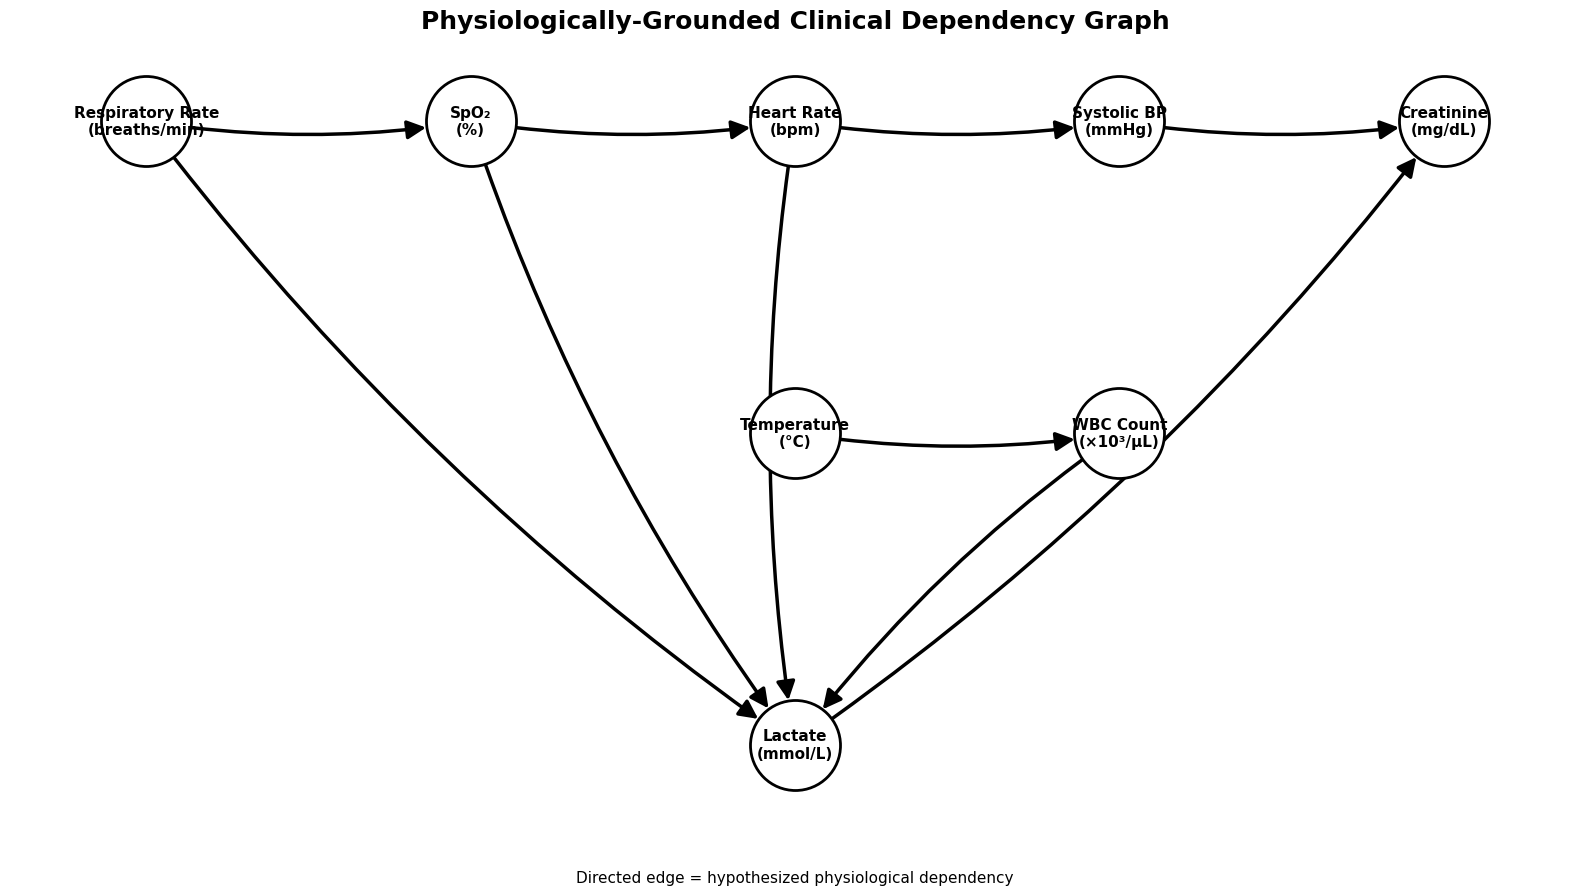

In [148]:
# ============================================================
# STEP 9 — FINAL PRESENTATION-QUALITY PHYSIOLOGICAL GRAPH
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()

# ------------------------------------------------------------
# Human-readable physiological node names
# ------------------------------------------------------------

NODE_LABELS = {
    0: "Respiratory Rate\n(breaths/min)",
    1: "SpO₂\n(%)",
    2: "Heart Rate\n(bpm)",
    3: "Systolic BP\n(mmHg)",
    4: "Temperature\n(°C)",
    5: "Lactate\n(mmol/L)",
    6: "Creatinine\n(mg/dL)",
    7: "WBC Count\n(×10³/µL)"
}

# Add nodes
for node_id in range(len(GRAPH_FEATURES)):
    G.add_node(node_id)

# Add EXACT existing edges
for source, target in zip(
    EDGE_INDEX[0].tolist(),
    EDGE_INDEX[1].tolist()
):
    G.add_edge(source, target)

# ------------------------------------------------------------
# Clear physiological layout
# ------------------------------------------------------------

pos = {
    0: (0, 3.0),       # Respiratory Rate
    1: (2.5, 3.0),     # SpO2
    2: (5.0, 3.0),     # Heart Rate
    3: (7.5, 3.0),     # SBP
    6: (10.0, 3.0),    # Creatinine

    4: (5.0, 0.5),     # Temperature
    7: (7.5, 0.5),     # WBC
    5: (5.0, -2.0),    # Lactate
}

plt.figure(figsize=(16, 9))

# Nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=4200,
    node_color="white",
    edgecolors="black",
    linewidths=2
)

# Directed edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=28,
    arrowstyle="-|>",
    width=2.5,
    edge_color="black",
    node_size=4200,
    connectionstyle="arc3,rad=0.08",
    min_source_margin=15,
    min_target_margin=20
)

# Labels
nx.draw_networkx_labels(
    G,
    pos,
    labels=NODE_LABELS,
    font_size=11,
    font_weight="bold"
)

plt.title(
    "Physiologically-Grounded Clinical Dependency Graph",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.text(
    5,
    -3.1,
    "Directed edge = hypothesized physiological dependency",
    ha="center",
    fontsize=11
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [149]:
# ============================================================
# CLEAN MISSING-DATA AUDIT TABLE
# ============================================================

def make_clean_missing_audit(before, after, dataset_name):

    rows = []

    for feature in GRAPH_FEATURES:

        missing_before = before[feature].isna().sum()
        missing_after = after[feature].isna().sum()

        values_filled = missing_before - missing_after

        recovery_percent = (
            values_filled / missing_before * 100
            if missing_before > 0 else 0
        )

        rows.append({
            "Dataset": dataset_name,
            "Feature": feature,

            "Rows Before": len(before),
            "Rows After": len(after),
            "Rows Added": len(after) - len(before),

            "Missing Values Before": missing_before,
            "Missing Values Filled": values_filled,
            "Missing Values Remaining": missing_after,

            "Missing Rate Before (%)":
                round(missing_before / len(before) * 100, 2),

            "Missing Rate After (%)":
                round(missing_after / len(after) * 100, 2),

            "Missing Values Recovered (%)":
                round(recovery_percent, 2)
        })

    return pd.DataFrame(rows)


clean_missing_audit = pd.concat([
    make_clean_missing_audit(
        train_raw,
        train_filled,
        "TRAIN"
    ),

    make_clean_missing_audit(
        val_raw,
        val_filled,
        "VALIDATION"
    ),

    make_clean_missing_audit(
        test_raw,
        test_filled,
        "TEST"
    )
], ignore_index=True)

display(clean_missing_audit)

,Dataset,Feature,Rows Before,Rows After,Rows Added,Missing Values Before,Missing Values Filled,Missing Values Remaining,Missing Rate Before (%),Missing Rate After (%),Missing Values Recovered (%)
0,TRAIN,resp_rate,5553096,5767242,214146,78636,77033,1603,1.42,0.03,97.96
1,TRAIN,spo2,5553096,5767242,214146,110328,109734,594,1.99,0.01,99.46
2,TRAIN,heart_rate,5553096,5767242,214146,20060,20059,1,0.36,0.00,100.00
3,TRAIN,sbp,5553096,5767242,214146,2040529,1992971,47558,36.75,0.82,97.67
4,TRAIN,temperature,5553096,5767242,214146,5311536,720186,4591350,95.65,79.61,13.56
5,TRAIN,lactate,5553096,5767242,214146,5357516,3818324,1539192,96.48,26.69,71.27
6,TRAIN,creatinine,5553096,5767242,214146,5157662,5098880,58782,92.88,1.02,98.86
7,TRAIN,wbc,5553096,5767242,214146,5206191,5142328,63863,93.75,1.11,98.77
8,VALIDATION,resp_rate,1169538,1232929,63391,16964,16289,675,1.45,0.05,96.02
9,VALIDATION,spo2,1169538,1232929,63391,23849,23711,138,2.04,0.01,99.42


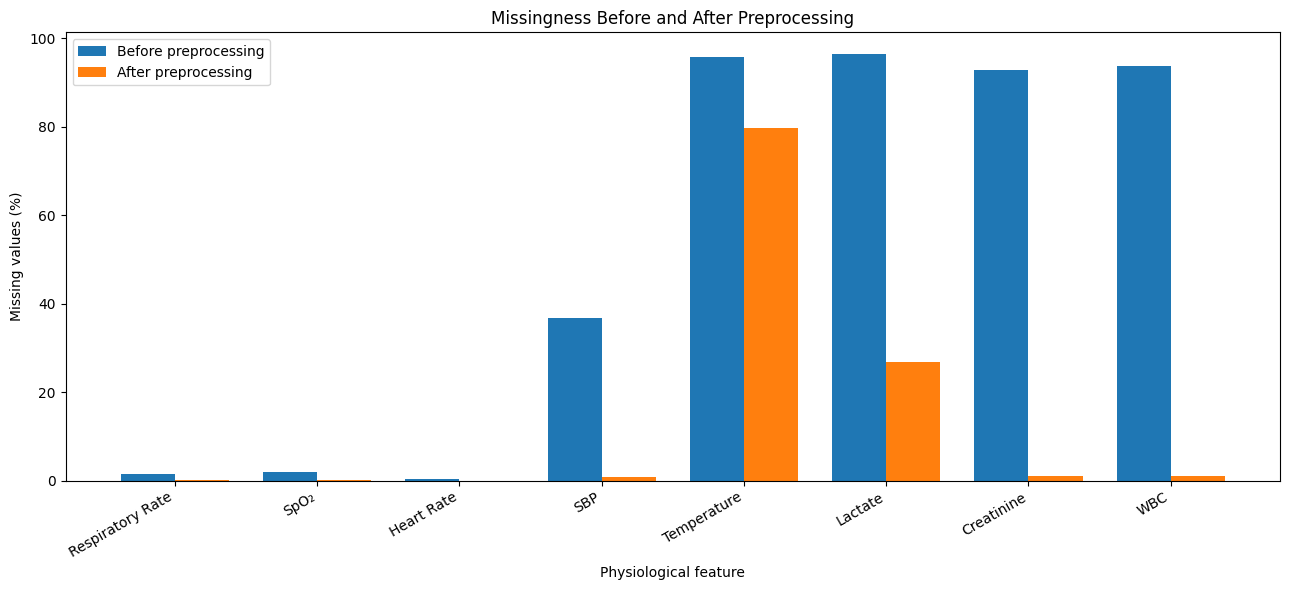

In [150]:
# ============================================================
# STEP 10 — MISSINGNESS BEFORE vs AFTER PREPROCESSING
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Use the TRAIN audit for the main preprocessing visualization
audit_plot = clean_missing_audit[
    clean_missing_audit["Dataset"] == "TRAIN"
].copy()

features = audit_plot["Feature"].tolist()

before = audit_plot["Missing Rate Before (%)"].to_numpy()
after = audit_plot["Missing Rate After (%)"].to_numpy()

x = np.arange(len(features))
width = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    before,
    width,
    label="Before preprocessing"
)

plt.bar(
    x + width / 2,
    after,
    width,
    label="After preprocessing"
)

plt.xticks(
    x,
    [
        "Respiratory Rate",
        "SpO₂",
        "Heart Rate",
        "SBP",
        "Temperature",
        "Lactate",
        "Creatinine",
        "WBC"
    ],
    rotation=30,
    ha="right"
)

plt.ylabel("Missing values (%)")
plt.xlabel("Physiological feature")
plt.title("Missingness Before and After Preprocessing")
plt.legend()

plt.tight_layout()
plt.show()

Sample ICU stay: 30000213
Time: 2162-06-21 05:00:00 → 2162-06-22 04:00:00


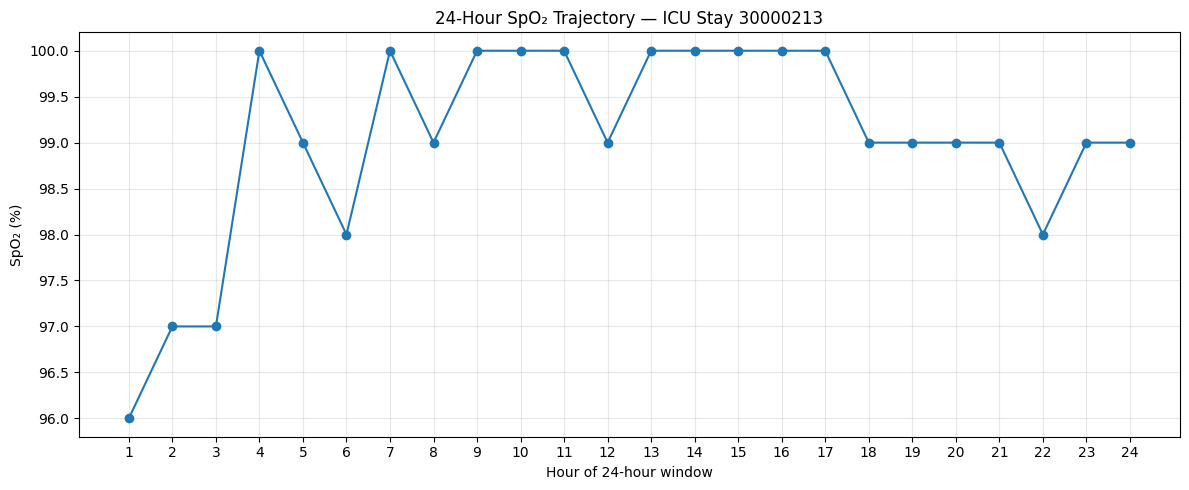

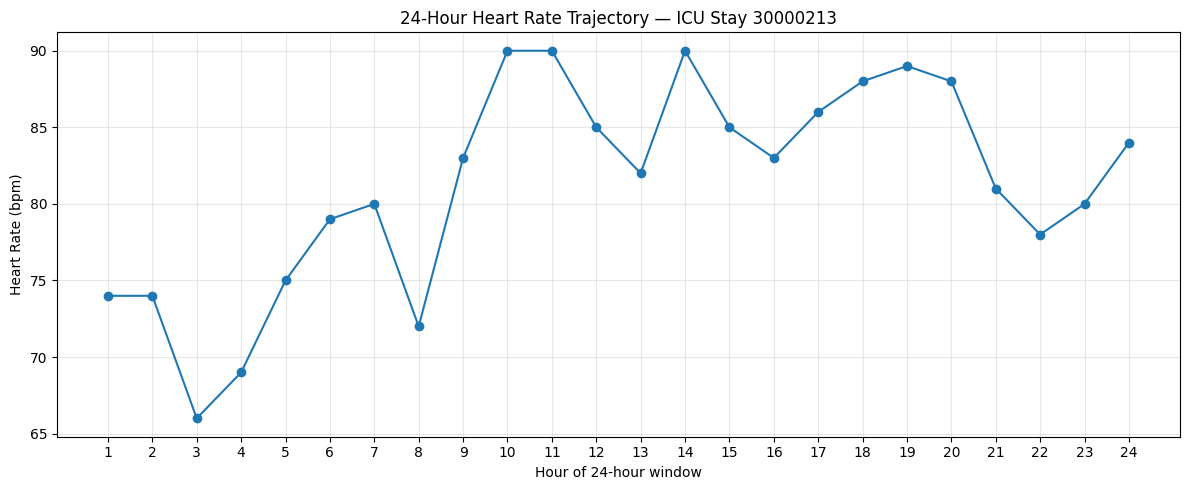

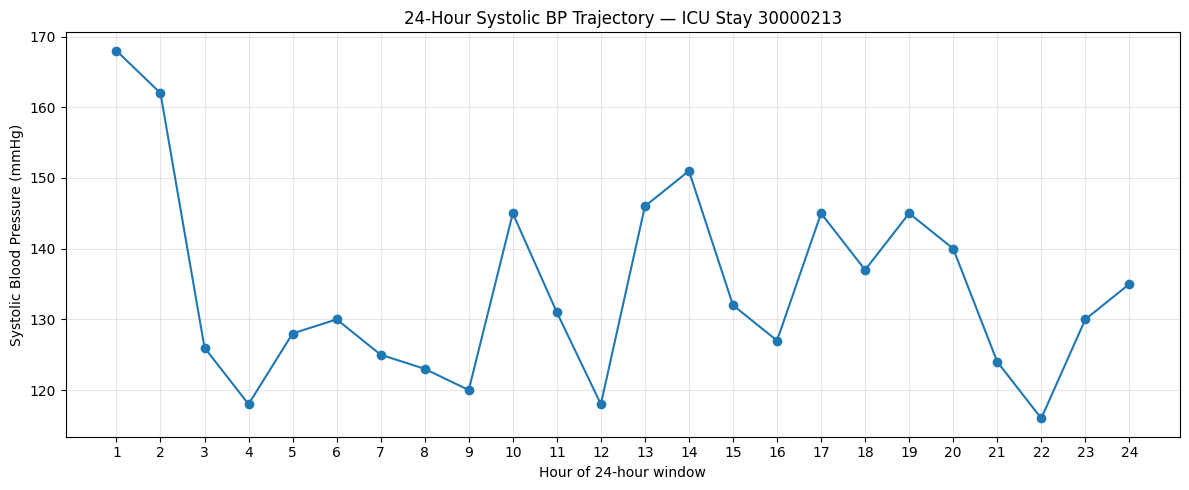

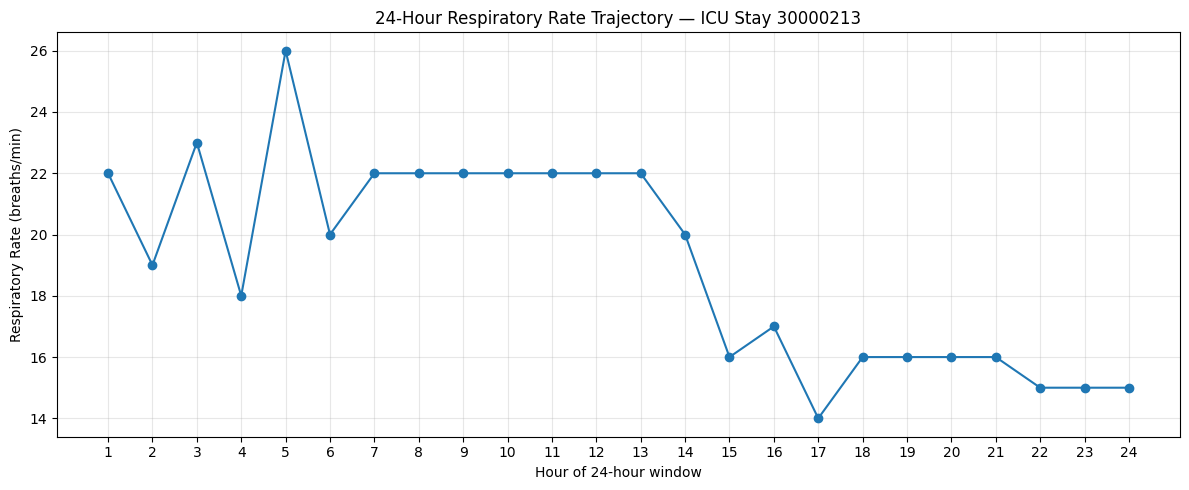

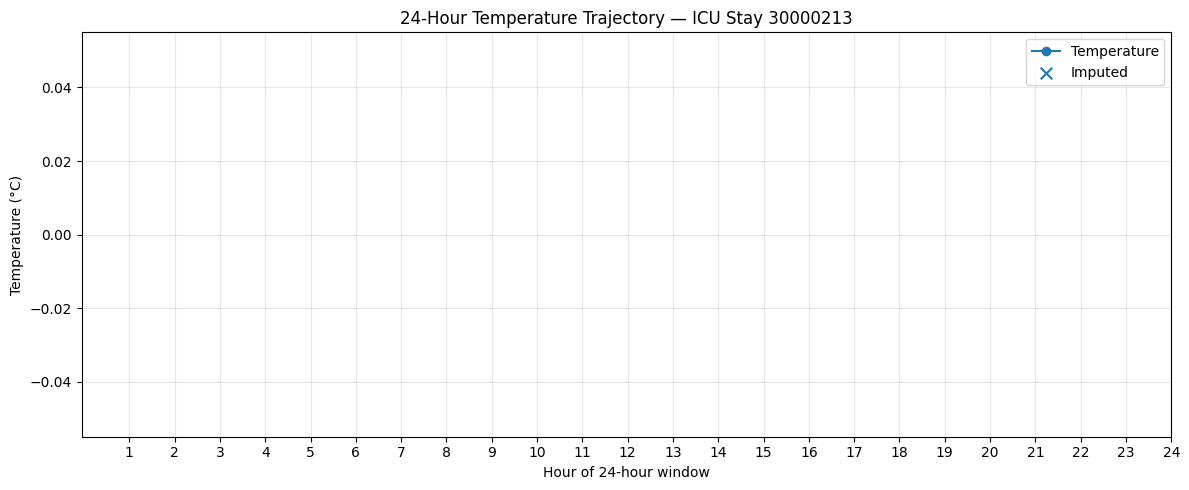

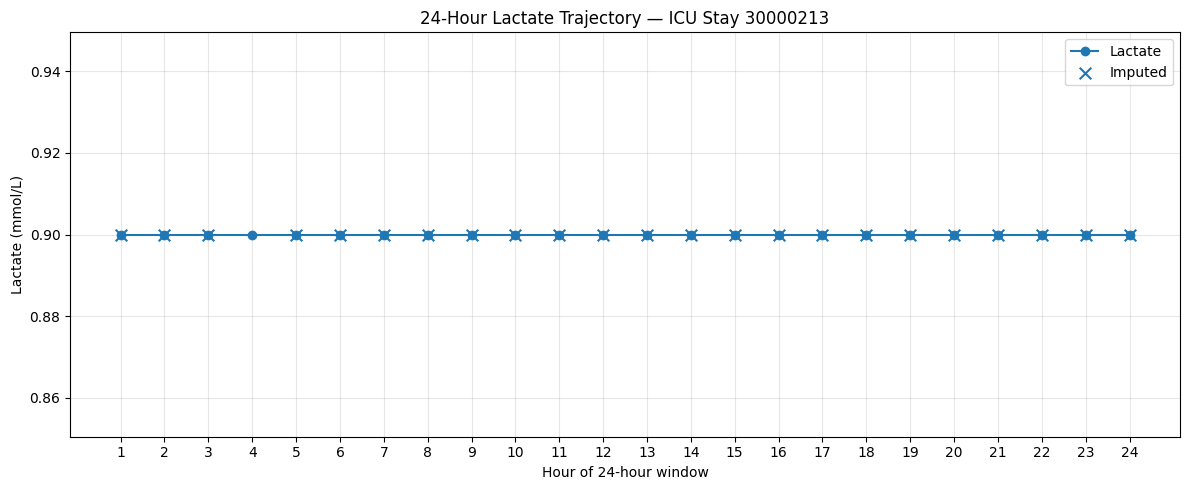

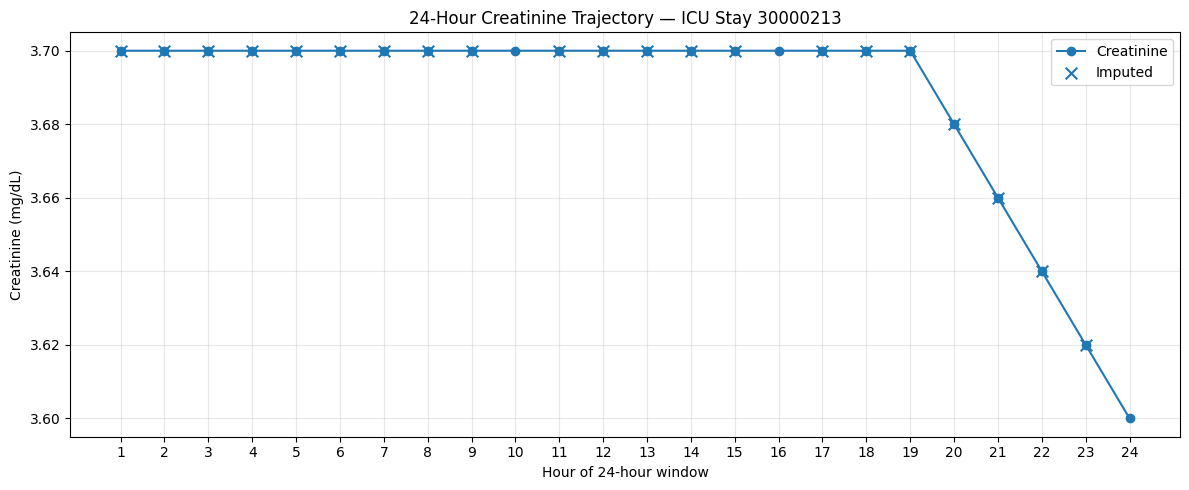

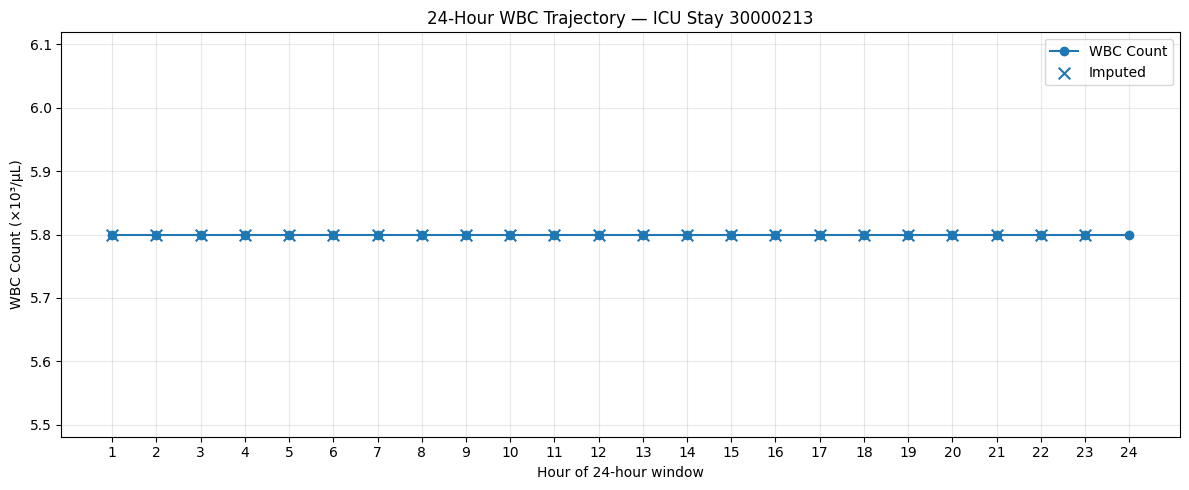

In [157]:
# ============================================================
# STEP 11 — REAL 24-HOUR PHYSIOLOGICAL TRAJECTORY
# ============================================================

import matplotlib.pyplot as plt

# Find a stay with at least 24 hourly observations
eligible_stays = (
    train_filled.groupby("stay_id")
    .size()
)

sample_stay = eligible_stays[
    eligible_stays >= 24
].index[0]

sample_24h = (
    train_filled[
        train_filled["stay_id"] == sample_stay
    ]
    .sort_values("hour")
    .iloc[:24]
    .copy()
)

print("Sample ICU stay:", sample_stay)
print("Time:", sample_24h["hour"].iloc[0],
      "→", sample_24h["hour"].iloc[-1])

# ------------------------------------------------------------
# SpO₂ — actual clinical values
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 25),
    sample_24h["spo2"],
    marker="o"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("SpO₂ (%)")
plt.title(
    f"24-Hour SpO₂ Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(range(1, 25))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 11B — 24-HOUR HEART RATE TRAJECTORY
# SAME ICU STAY AS SpO₂
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 25),
    sample_24h["heart_rate"],
    marker="o"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Heart Rate (bpm)")
plt.title(
    f"24-Hour Heart Rate Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(range(1, 25))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 11C — 24-HOUR SYSTOLIC BP TRAJECTORY
# SAME ICU STAY AND SAME WINDOW
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 25),
    sample_24h["sbp"],
    marker="o"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.title(
    f"24-Hour Systolic BP Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(range(1, 25))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 11D
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

hours_24 = range(1, 25)

# ============================================================
# 1. RESPIRATORY RATE
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    hours_24,
    sample_24h["resp_rate"],
    marker="o"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Respiratory Rate (breaths/min)")
plt.title(
    f"24-Hour Respiratory Rate Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(hours_24)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# STEP 11E TEMPERATURE
# ============================================================

feature = "temperature"

# Original missingness information
temp_missing = sample_24h[
    f"{feature}_missing"
].astype(bool)

plt.figure(figsize=(12, 5))

plt.plot(
    hours_24,
    sample_24h[feature],
    marker="o",
    label="Temperature"
)

# Mark imputed observations
plt.scatter(
    [h for h, missing in zip(hours_24, temp_missing) if missing],
    sample_24h.loc[temp_missing, feature],
    marker="x",
    s=70,
    label="Imputed"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Temperature (°C)")
plt.title(
    f"24-Hour Temperature Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(hours_24)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# STEP 11F LACTATE
# ============================================================

feature = "lactate"

lactate_missing = sample_24h[
    f"{feature}_missing"
].astype(bool)

plt.figure(figsize=(12, 5))

plt.plot(
    hours_24,
    sample_24h[feature],
    marker="o",
    label="Lactate"
)

plt.scatter(
    [h for h, missing in zip(hours_24, lactate_missing) if missing],
    sample_24h.loc[lactate_missing, feature],
    marker="x",
    s=70,
    label="Imputed"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Lactate (mmol/L)")
plt.title(
    f"24-Hour Lactate Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(hours_24)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# STEP 11G CREATININE
# ============================================================

feature = "creatinine"

creatinine_missing = sample_24h[
    f"{feature}_missing"
].astype(bool)

plt.figure(figsize=(12, 5))

plt.plot(
    hours_24,
    sample_24h[feature],
    marker="o",
    label="Creatinine"
)

plt.scatter(
    [h for h, missing in zip(hours_24, creatinine_missing) if missing],
    sample_24h.loc[creatinine_missing, feature],
    marker="x",
    s=70,
    label="Imputed"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("Creatinine (mg/dL)")
plt.title(
    f"24-Hour Creatinine Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(hours_24)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# STEP 11H WBC COUNT
# ============================================================

feature = "wbc"

wbc_missing = sample_24h[
    f"{feature}_missing"
].astype(bool)

plt.figure(figsize=(12, 5))

plt.plot(
    hours_24,
    sample_24h[feature],
    marker="o",
    label="WBC Count"
)

plt.scatter(
    [h for h, missing in zip(hours_24, wbc_missing) if missing],
    sample_24h.loc[wbc_missing, feature],
    marker="x",
    s=70,
    label="Imputed"
)

plt.xlabel("Hour of 24-hour window")
plt.ylabel("WBC Count (×10³/µL)")
plt.title(
    f"24-Hour WBC Trajectory — ICU Stay {sample_stay}"
)

plt.xticks(hours_24)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [155]:
# ============================================================
# STEP 12 — PATIENT-SPECIFIC PHYSIOLOGICAL GRAPH
# SAME ICU STAY AND SAME 24-HOUR WINDOW
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# ------------------------------------------------------------
# Find the same stay/window in the raw graph data
# ------------------------------------------------------------

raw_sample = graph_data[
    (graph_data["stay_id"] == sample_stay) &
    (graph_data["hour"].isin(sample_24h["hour"]))
].copy()

missing_columns = [
    f"{feature}_missing"
    for feature in GRAPH_FEATURES
]

# Number of originally observed physiological features
raw_sample["observed_count"] = (
    len(GRAPH_FEATURES)
    - raw_sample[missing_columns].sum(axis=1)
)

# Pick the hour with maximum originally observed measurements
selected_row = raw_sample.loc[
    raw_sample["observed_count"].idxmax()
]

selected_hour = selected_row["hour"]

# Get the corresponding preprocessed values
value_row = sample_24h[
    sample_24h["hour"] == selected_hour
].iloc[0]

print("ICU stay:", sample_stay)
print("Selected hour:", selected_hour)
print(
    "Originally observed features:",
    int(selected_row["observed_count"]),
    "/",
    len(GRAPH_FEATURES)
)

ICU stay: 30000213
Selected hour: 2162-06-22 04:00:00
Originally observed features: 6 / 8


In [158]:
# ============================================================
# CHANGE — ORIGINAL CLINICAL 24-HOUR WINDOW
# ============================================================

# Use the SAME ICU stay and SAME 24 hours
sample_original_24h = (
    graph_data[
        (graph_data["stay_id"] == sample_stay) &
        (graph_data["hour"].isin(sample_24h["hour"]))
    ]
    .sort_values("hour")
    .reset_index(drop=True)
)

print("ICU stay:", sample_stay)
print(
    "Window:",
    sample_original_24h["hour"].iloc[0],
    "→",
    sample_original_24h["hour"].iloc[-1]
)

print("Shape:", sample_original_24h.shape)

display(
    sample_original_24h[
        ["stay_id", "hour"] + GRAPH_FEATURES
    ]
)

ICU stay: 30000213
Window: 2162-06-21 05:00:00 → 2162-06-22 04:00:00
Shape: (24, 18)


,stay_id,hour,resp_rate,spo2,heart_rate,sbp,temperature,lactate,creatinine,wbc
0,30000213,2162-06-21 05:00:00,22.0,96.0,74.0,168.0,NaN,NaN,NaN,NaN
1,30000213,2162-06-21 06:00:00,19.0,97.0,74.0,162.0,NaN,NaN,NaN,NaN
2,30000213,2162-06-21 07:00:00,23.0,97.0,66.0,126.0,NaN,NaN,NaN,NaN
3,30000213,2162-06-21 08:00:00,18.0,100.0,69.0,118.0,NaN,0.9,NaN,NaN
4,30000213,2162-06-21 09:00:00,26.0,99.0,75.0,128.0,NaN,NaN,NaN,NaN
5,30000213,2162-06-21 10:00:00,20.0,98.0,79.0,130.0,NaN,NaN,NaN,NaN
6,30000213,2162-06-21 11:00:00,22.0,100.0,80.0,125.0,NaN,NaN,NaN,NaN
7,30000213,2162-06-21 12:00:00,22.0,99.0,72.0,123.0,NaN,NaN,NaN,NaN
8,30000213,2162-06-21 13:00:00,22.0,100.0,83.0,120.0,NaN,NaN,NaN,NaN
9,30000213,2162-06-21 14:00:00,22.0,100.0,90.0,145.0,NaN,NaN,3.7,NaN


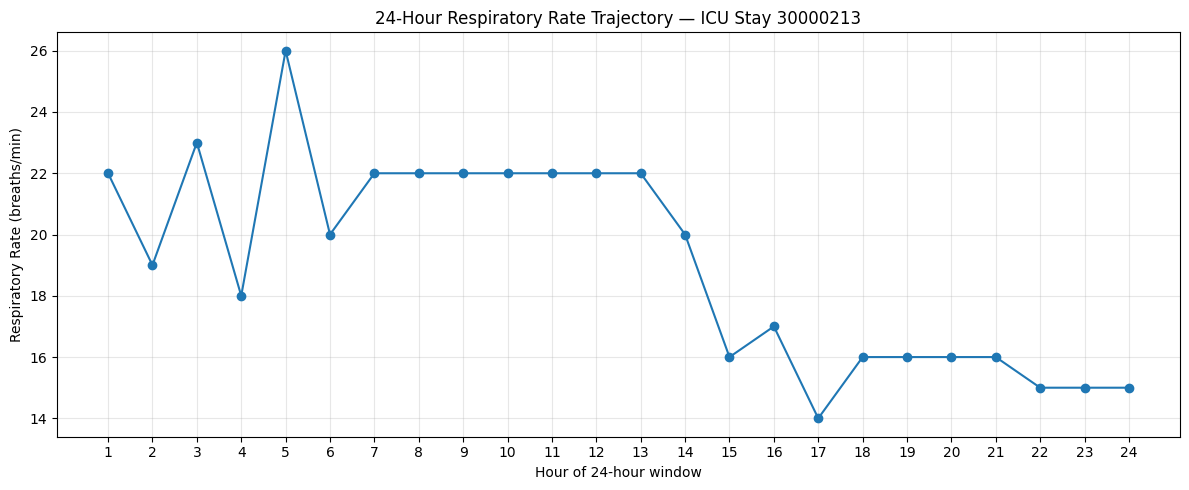

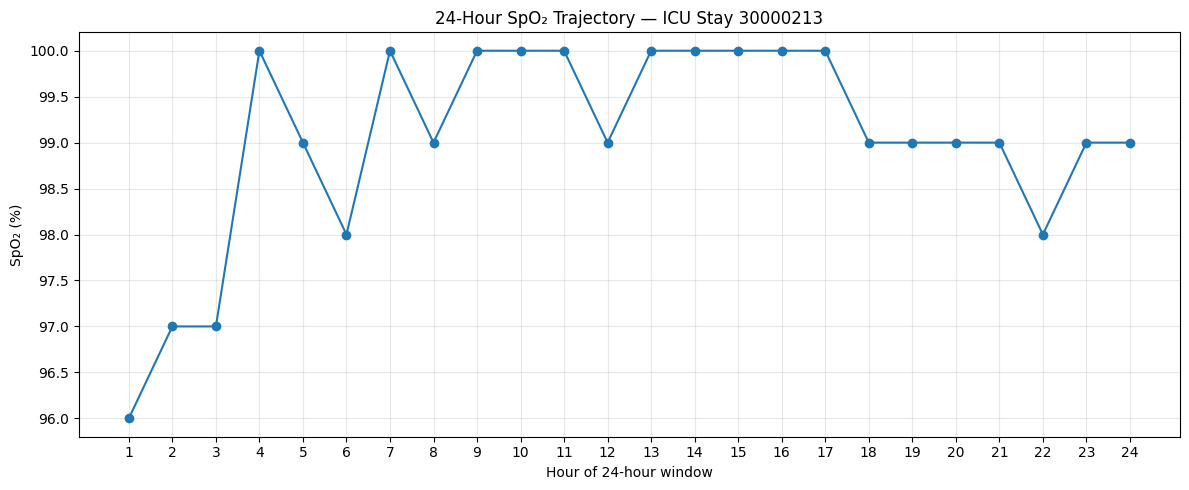

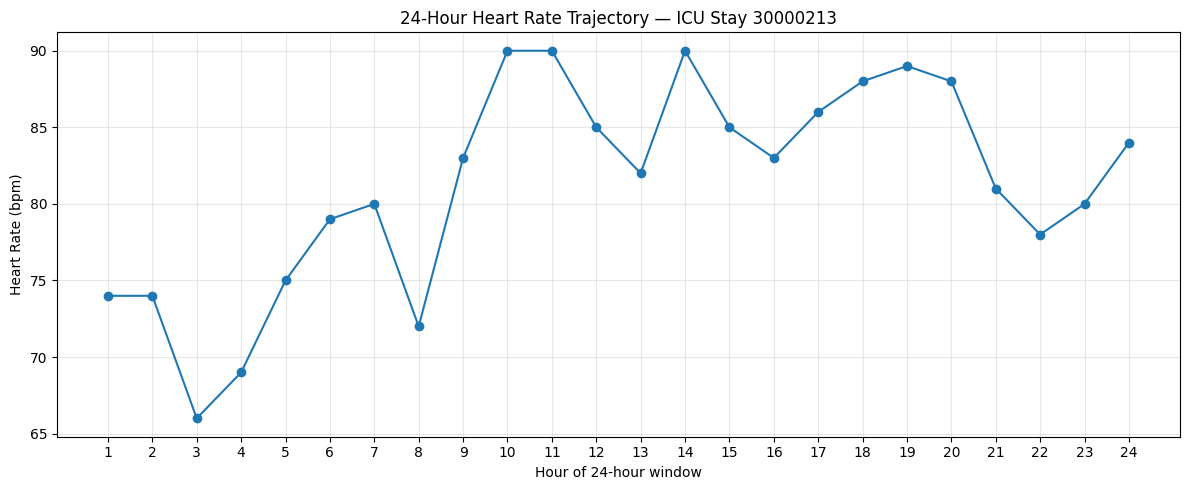

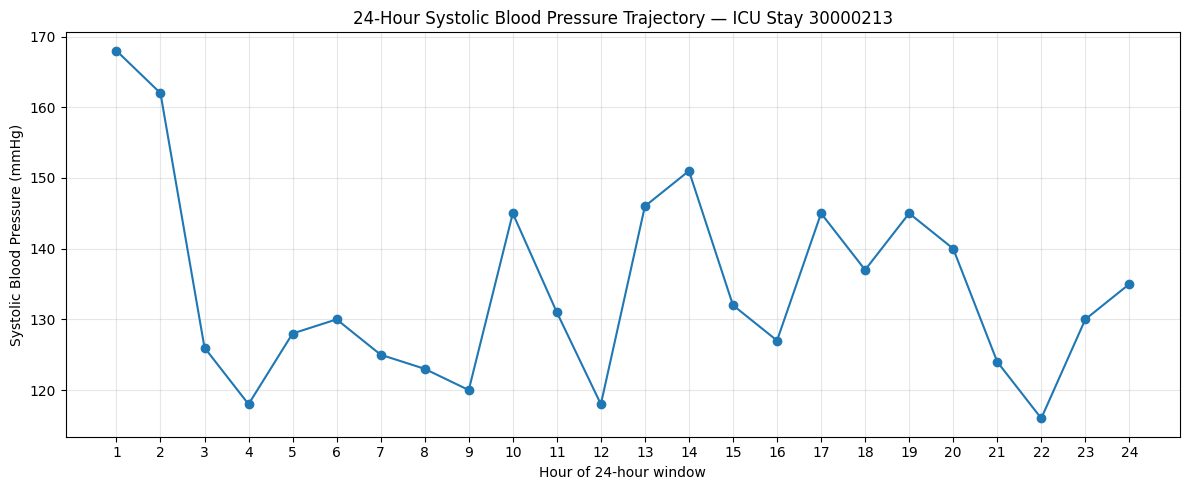

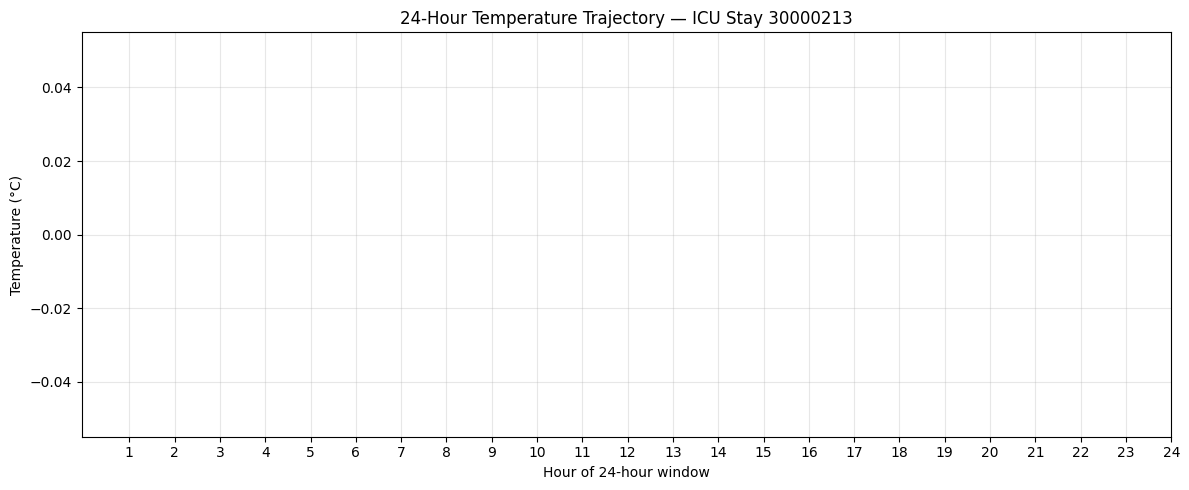

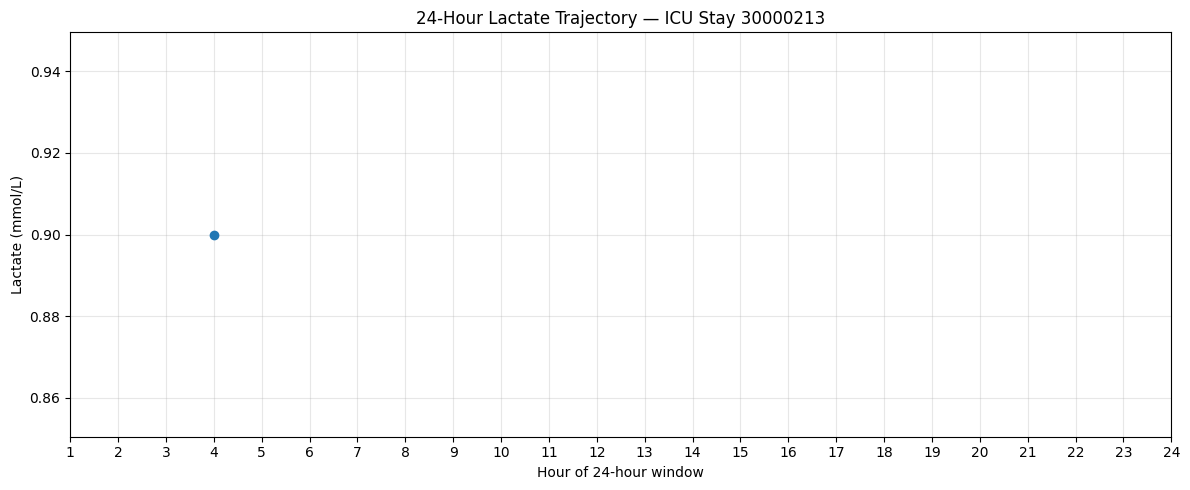

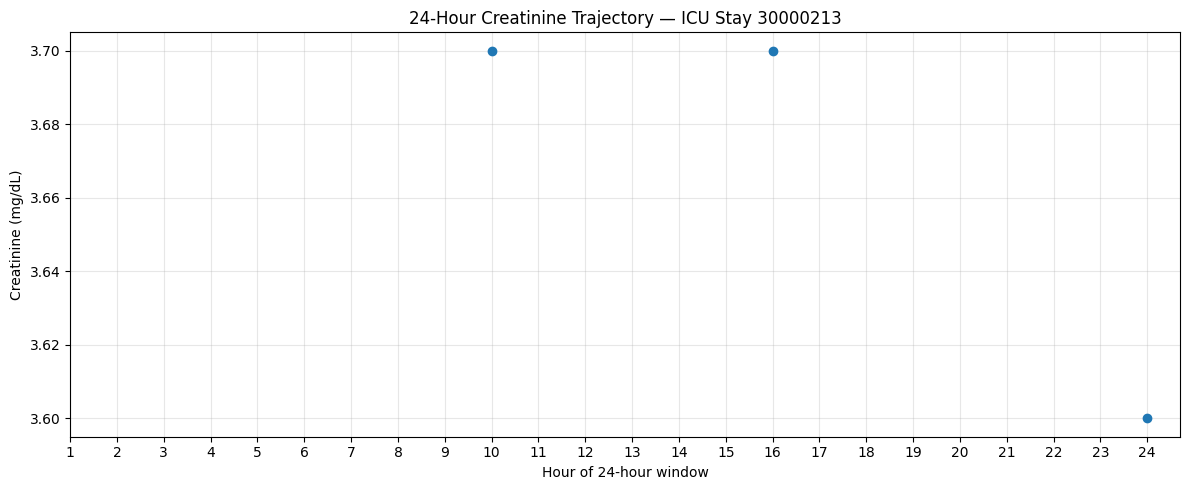

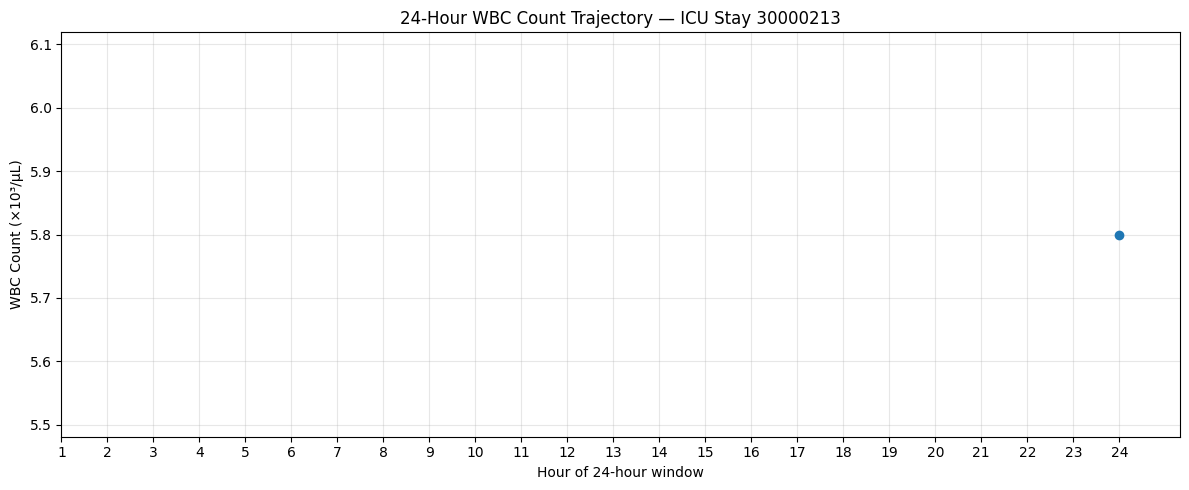

In [159]:
# ============================================================
# FINAL — ORIGINAL CLINICAL 24-HOUR TRAJECTORIES
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

hours = np.arange(1, 25)

plot_features = [
    ("resp_rate", "Respiratory Rate", "breaths/min"),
    ("spo2", "SpO₂", "%"),
    ("heart_rate", "Heart Rate", "bpm"),
    ("sbp", "Systolic Blood Pressure", "mmHg"),
    ("temperature", "Temperature", "°C"),
    ("lactate", "Lactate", "mmol/L"),
    ("creatinine", "Creatinine", "mg/dL"),
    ("wbc", "WBC Count", "×10³/µL"),
]

for feature, display_name, unit in plot_features:

    values = sample_original_24h[feature]

    plt.figure(figsize=(12, 5))

    # ONLY ORIGINAL OBSERVATIONS
    plt.plot(
        hours,
        values,
        marker="o",
        linestyle="-"
    )

    plt.xlabel("Hour of 24-hour window")
    plt.ylabel(f"{display_name} ({unit})")

    plt.title(
        f"24-Hour {display_name} Trajectory — "
        f"ICU Stay {sample_stay}"
    )

    plt.xticks(hours)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

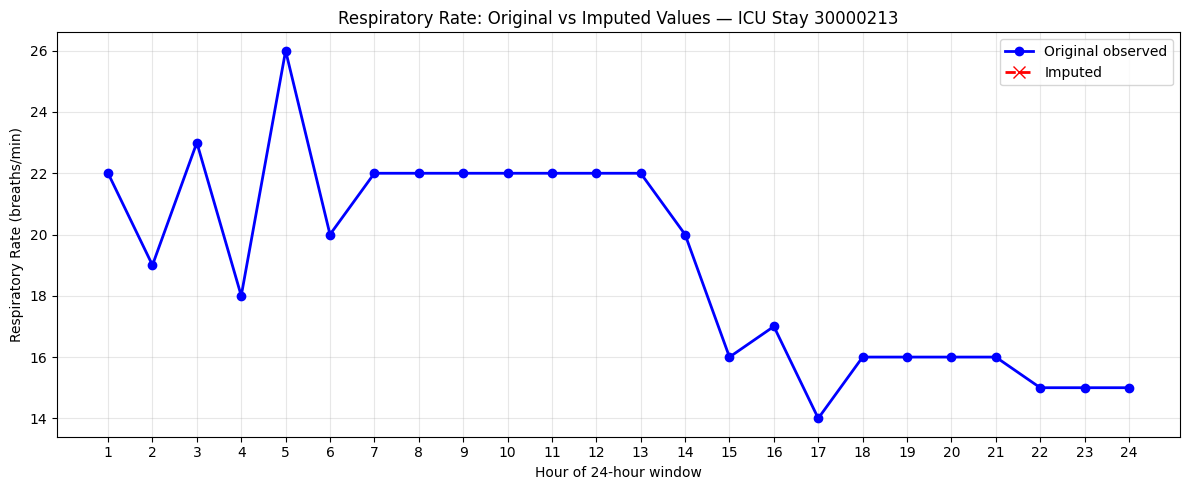

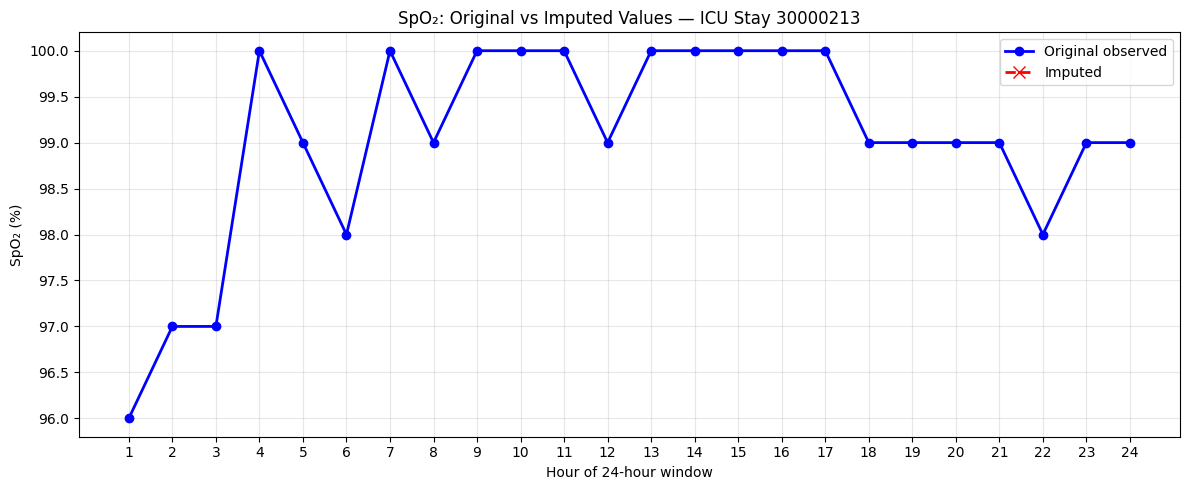

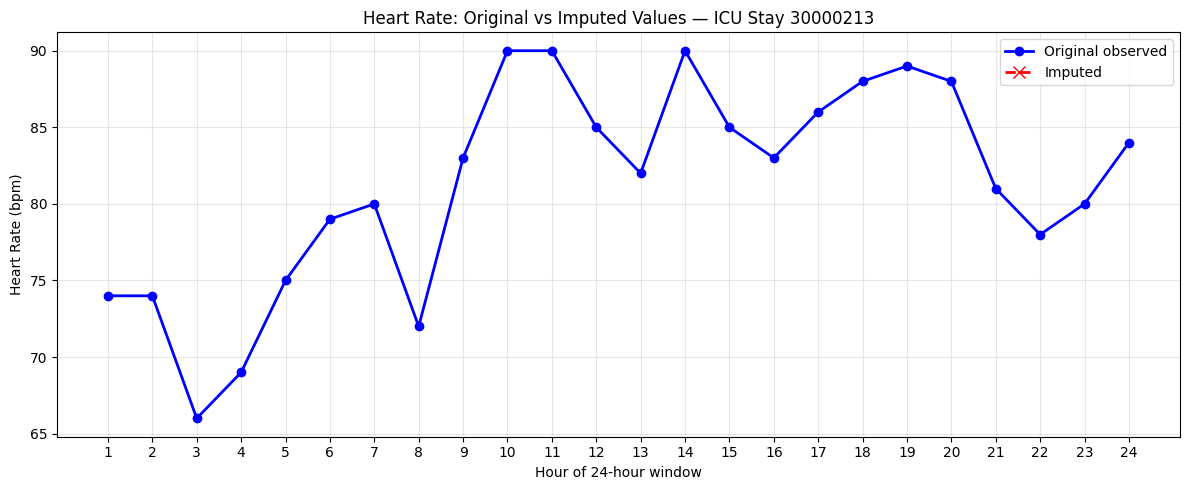

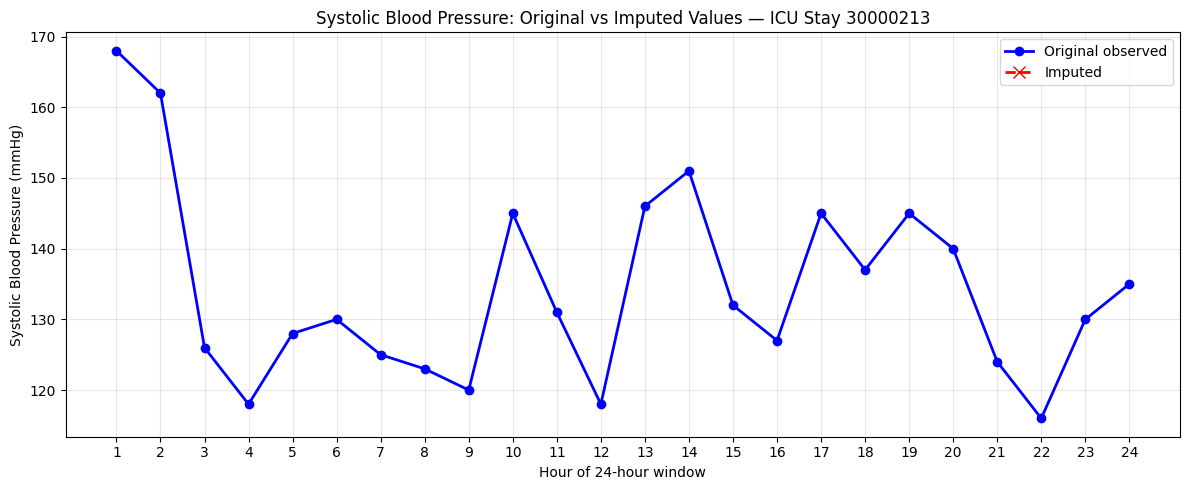

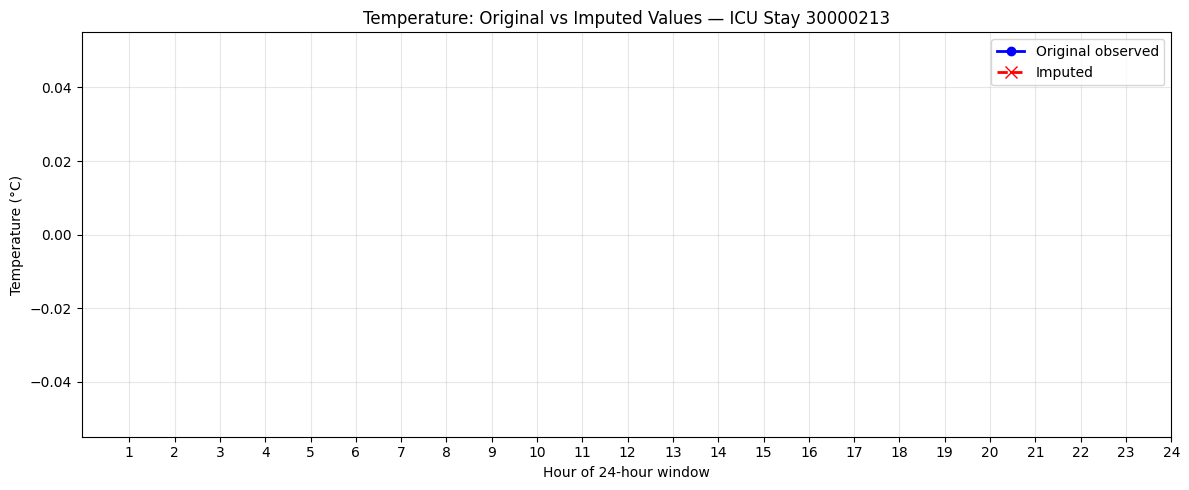

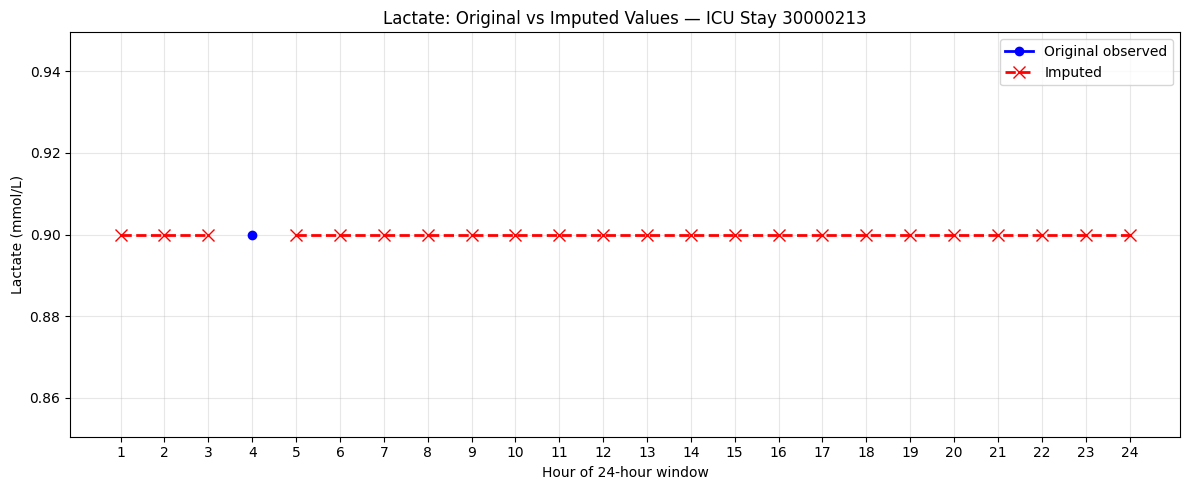

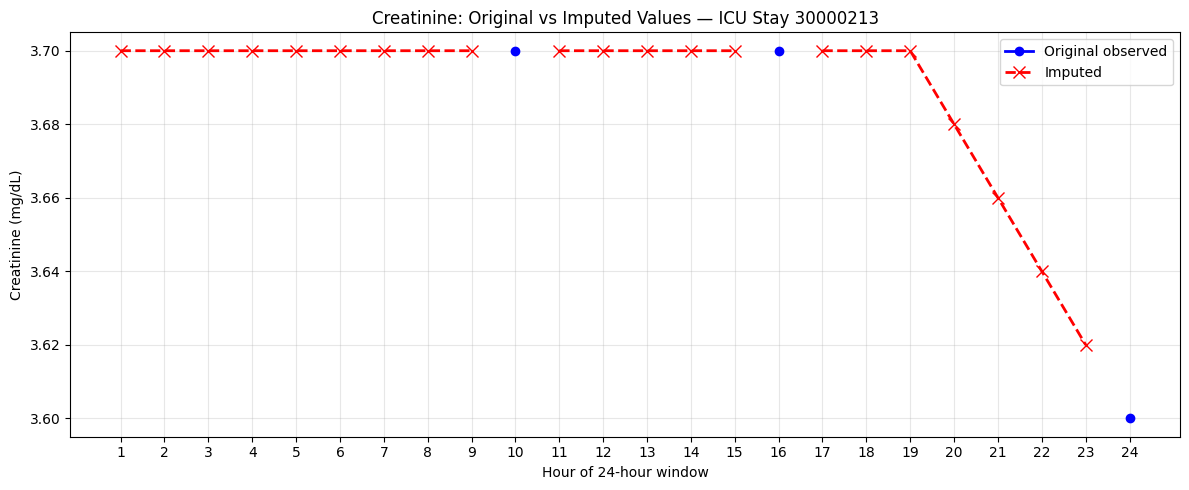

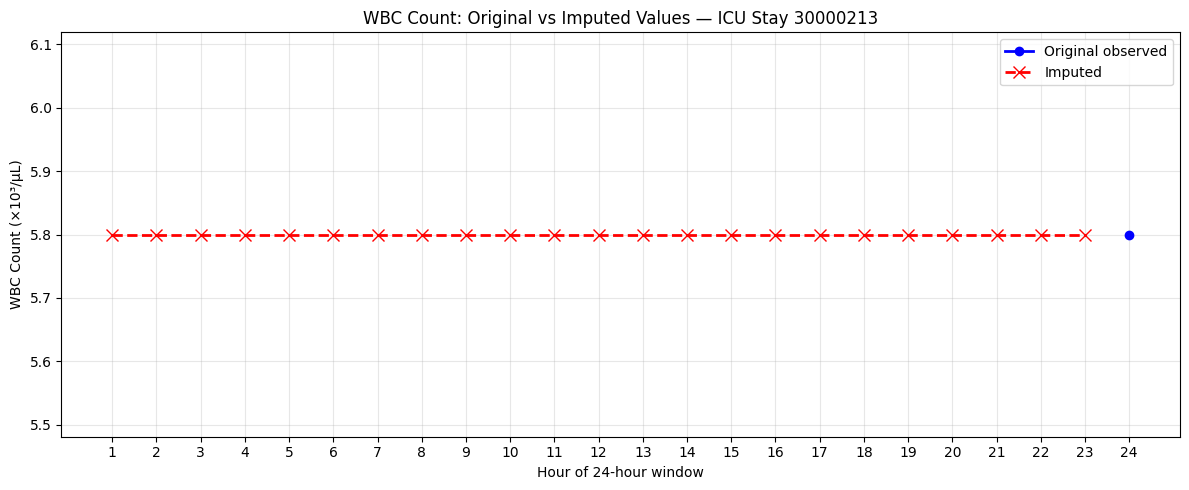

In [161]:
# ============================================================
# ORIGINAL vs IMPUTED VALUES
# ============================================================

for feature, display_name, unit in plot_features:

    original = sample_original_24h[feature].to_numpy()
    model_values = sample_24h[feature].to_numpy()

    was_missing = (
        sample_original_24h[f"{feature}_missing"]
        .astype(bool)
        .to_numpy()
    )

    # Original observations only
    observed_values = np.where(
        was_missing,
        np.nan,
        original
    )

    # Imputed values only
    imputed_values = np.where(
        was_missing,
        model_values,
        np.nan
    )

    plt.figure(figsize=(12, 5))

    # --------------------------------------------------------
    # ORIGINAL OBSERVED VALUES
    # --------------------------------------------------------
    plt.plot(
        hours,
        observed_values,
        color="blue",
        marker="o",
        linewidth=2,
        label="Original observed"
    )

    # --------------------------------------------------------
    # IMPUTED VALUES
    # --------------------------------------------------------
    plt.plot(
        hours,
        imputed_values,
        color="red",
        marker="x",
        markersize=8,
        linewidth=2,
        linestyle="--",
        label="Imputed"
    )

    plt.xlabel("Hour of 24-hour window")
    plt.ylabel(f"{display_name} ({unit})")

    plt.title(
        f"{display_name}: Original vs Imputed Values — "
        f"ICU Stay {sample_stay}"
    )

    plt.xticks(hours)
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

### Visualization

In [168]:
# ============================================================
# EXPORT REAL PATIENT DATA — NaN SAFE
# ============================================================

import json
import math
from pathlib import Path

# ------------------------------------------------------------
# 1. Get the SAME real 24-hour patient window
# ------------------------------------------------------------

real_24h = (
    graph_data[
        (graph_data["stay_id"] == sample_stay) &
        (graph_data["hour"].isin(sample_24h["hour"]))
    ]
    .sort_values("hour")
    .reset_index(drop=True)
)

assert len(real_24h) == 24, (
    f"Expected 24 rows, got {len(real_24h)}"
)

# ------------------------------------------------------------
# 2. Select only the required columns
# ------------------------------------------------------------

export_columns = (
    ["stay_id", "hour"]
    + GRAPH_FEATURES
    + [f"{feature}_missing" for feature in GRAPH_FEATURES]
)

export_df = real_24h[export_columns].copy()

# Timestamp → string
export_df["hour"] = export_df["hour"].astype(str)

# ------------------------------------------------------------
# 3. Convert EVERY NaN / NumPy value safely
# ------------------------------------------------------------

def json_safe(value):

    # Missing numerical value
    if value is None:
        return None

    try:
        if math.isnan(float(value)):
            return None
    except (TypeError, ValueError):
        pass

    # NumPy scalar → native Python value
    if hasattr(value, "item"):
        try:
            return value.item()
        except ValueError:
            pass

    return value


records = []

for _, row in export_df.iterrows():

    record = {}

    for column in export_columns:
        record[column] = json_safe(row[column])

    records.append(record)

# ------------------------------------------------------------
# 4. Graph structure
# ------------------------------------------------------------

edges = [
    [
        int(source),
        int(target)
    ]
    for source, target in zip(
        EDGE_INDEX[0].tolist(),
        EDGE_INDEX[1].tolist()
    )
]

# ------------------------------------------------------------
# 5. Build final JSON object
# ------------------------------------------------------------

patient_data = {
    "stay_id": int(sample_stay),

    "window_start": str(
        real_24h["hour"].iloc[0]
    ),

    "window_end": str(
        real_24h["hour"].iloc[-1]
    ),

    "features": [
        str(feature)
        for feature in GRAPH_FEATURES
    ],

    "edges": edges,

    "data": records
}

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

project_root = Path.cwd().parent

visualization_dir = (
    project_root
    / "data"
    / "processed"
    / "visualization"
)

visualization_dir.mkdir(
    parents=True,
    exist_ok=True
)

json_path = (
    visualization_dir
    / f"patient_{sample_stay}_24h.json"
)

with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        patient_data,
        f,
        indent=2,
        allow_nan=False
    )

print("✅ REAL PATIENT DATA EXPORTED")
print("--------------------------------")
print("ICU stay :", sample_stay)
print("Rows     :", len(records))
print("Features :", len(GRAPH_FEATURES))
print("Edges    :", len(edges))
print("File     :", json_path)

✅ REAL PATIENT DATA EXPORTED
--------------------------------
ICU stay : 30000213
Rows     : 24
Features : 8
Edges    : 10
File     : /Users/tejaramidi/Documents/fyp_icu/data/processed/visualization/patient_30000213_24h.json


Physiological features found:
✓ resp_rate
✓ spo2
✓ heart_rate
✓ sbp
✓ temperature
✓ lactate
✓ creatinine
✓ wbc

Figure saved to:
/Users/tejaramidi/Documents/fyp_icu/data/processed/icu_physiological_variables.png


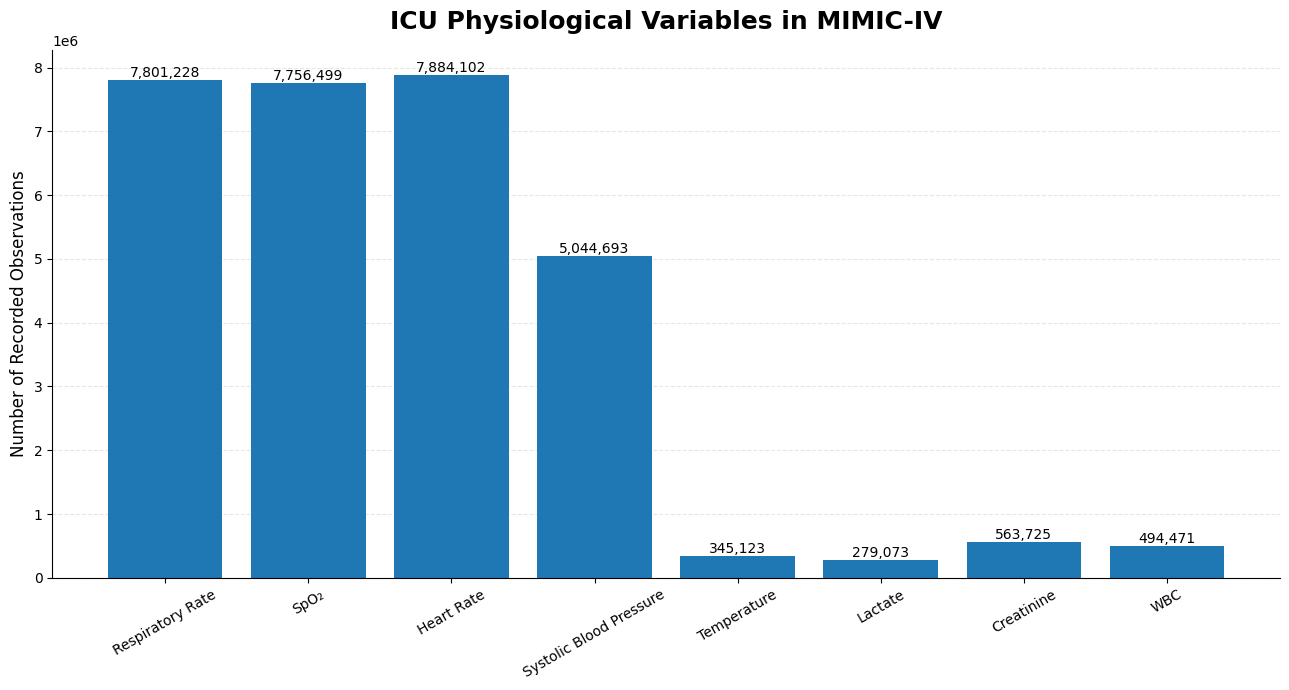

In [172]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# LOAD ACTUAL ICU GRAPH DATA
# ============================================================

PROJECT_DIR = Path("/Users/tejaramidi/Documents/fyp_icu")

file_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "icu_graph_hourly_raw.parquet"
)

df = pd.read_parquet(file_path)

# ============================================================
# PHYSIOLOGICAL FEATURES
# ============================================================

features = [
    "resp_rate",
    "spo2",
    "heart_rate",
    "sbp",
    "temperature",
    "lactate",
    "creatinine",
    "wbc"
]

# ============================================================
# VERIFY
# ============================================================

missing = [f for f in features if f not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Physiological features found:")
for f in features:
    print("✓", f)

# ============================================================
# PLOT
# ============================================================

display_names = {
    "resp_rate": "Respiratory Rate",
    "spo2": "SpO₂",
    "heart_rate": "Heart Rate",
    "sbp": "Systolic Blood Pressure",
    "temperature": "Temperature",
    "lactate": "Lactate",
    "creatinine": "Creatinine",
    "wbc": "WBC"
}

fig, ax = plt.subplots(figsize=(13, 7))

# Just show presence of each physiological variable
# using the actual data columns.
counts = [
    df[f].notna().sum()
    for f in features
]

bars = ax.bar(
    [display_names[f] for f in features],
    counts
)

# ============================================================
# VALUES
# ============================================================

for bar, value in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# ============================================================
# FORMATTING
# ============================================================

ax.set_title(
    "ICU Physiological Variables in MIMIC-IV",
    fontsize=18,
    fontweight="bold",
    pad=15
)

ax.set_ylabel(
    "Number of Recorded Observations",
    fontsize=12
)

ax.tick_params(
    axis="x",
    rotation=30
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ============================================================
# SAVE
# ============================================================

output = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "icu_physiological_variables.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved to:")
print(output)

plt.show()